# Assignment 10 --- Image Segmentation

**Md. Shoaib Abdullah Khan — ID: 2010976135**

This notebook implements **Tasks 2, 3 and 4**. Task 1 is a written architectural question and is
answered in the report only, so it needs no code.

| Task | Contents |
|---|---|
| **Task 2** | Seven segmentation models (U-Net, U-Net++, FPN, Attention U-Net, BASNet, DeepLabV3+, SegFormer) trained on the **Oxford-IIIT Pet** dataset under *identical* settings, evaluated with IoU / Dice / Pixel-Accuracy / Precision / Recall / F1 / mean-IoU, and compared in one table. |
| **Task 3** | **BRAG-UNet**, a custom architecture (ASPP bridge, attention-gated skips, *scale-gated multi-scale fusion*, *boundary-refinement head*, *boundary-aware loss*), trained with the same settings and compared against all seven. |
| **Task 4** | Self-captured phone photographs, annotated by hand, pushed through every trained model, scored with the same metrics, and analysed for domain shift. |

### Experimental design

All six CNN models are written from scratch on **one shared ImageNet-pretrained ResNet-34
encoder**, so the *only* thing that differs between them is the **decoder**. That is what makes
the Task 2C comparison meaningful: any difference in the table is attributable to decoder design
rather than to a different backbone.

Two deliberate exceptions, both noted again where they occur:

* **SegFormer** keeps its own hierarchical Mix-Transformer encoder --- that encoder *is* the
  model's contribution, so swapping it out would defeat the point of including it.
* **DeepLabV3+** dilates the final ResNet stage (output stride 16 instead of 32). The weights are
  the same ResNet-34 weights; the dilation *is* the architectural claim being tested.

## 0. Environment

Everything below runs on a single GPU. The install cell is idempotent --- skip it if the imports
in the next cell already succeed.

In [1]:
# Only `transformers` (SegFormer) and `albumentations` are non-standard here.
# %pip install -q torch torchvision transformers albumentations opencv-python scikit-learn matplotlib pandas pillow tqdm numpy scipy

## 1. Imports, global configuration and reproducibility

A single `CFG` object holds every experimental setting. Because *all* models read their
hyper-parameters from this one object, it is impossible for two models to accidentally be trained
with a different learning rate, epoch count or augmentation policy --- which is exactly the
guarantee the assignment's "same experimental settings" requirement needs.

In [2]:
import os, sys, json, time, math, random, warnings
from pathlib import Path
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from PIL import Image, ImageOps
import cv2
from scipy import ndimage as ndi
from tqdm import tqdm

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------- paths
ROOT    = Path.cwd()                       # .../Assignments/10
DATA    = ROOT / "data"
IMGDIR  = DATA / "images"
TRIDIR  = DATA / "annotations" / "trimaps"
LISTDIR = DATA / "annotations"
CACHE   = ROOT / "cache"
OUT     = ROOT / "outputs"
FIG     = OUT / "figures"
RES     = OUT / "results"
CKPT    = OUT / "checkpoints"
PHONE   = ROOT / "phone image"             # self-captured images (Task 4)
SELF    = ROOT / "selfcaptured"
for d in (CACHE, FIG, RES, CKPT, SELF / "masks", SELF / "review"):
    d.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------- config
@dataclass
class Config:
    img_size: int       = 256     # network input resolution (H = W)
    n_classes: int      = 3       # 0 background, 1 pet, 2 border
    val_frac: float     = 0.10    # carved out of the official trainval list
    batch: int          = 16
    epochs: int         = 30
    lr: float           = 3e-4
    weight_decay: float = 1e-4
    dice_w: float       = 0.5     # loss = CE + dice_w * SoftDice
    deep_sup_w: float   = 0.4     # weight on auxiliary deep-supervision outputs
    seed: int           = 42
    amp: bool           = True

CFG = Config()
CLASS_NAMES = ["background", "pet", "border"]
FG = 1                                     # index of the "pet" (foreground) class

def set_seed(s=CFG.seed):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEV.type == "cuda":
    torch.backends.cudnn.benchmark = True
    _p = torch.cuda.get_device_properties(0)
    HARDWARE = f"{_p.name}, {_p.total_memory/1e9:.1f} GB VRAM"
else:
    HARDWARE = "CPU only"

print(f"torch {torch.__version__} | device {DEV} | {HARDWARE}")
print(f"config {asdict(CFG)}")

torch 2.7.1+cu128 | device cuda | NVIDIA GeForce RTX 5070 Ti, 17.1 GB VRAM
config {'img_size': 256, 'n_classes': 3, 'val_frac': 0.1, 'batch': 16, 'epochs': 30, 'lr': 0.0003, 'weight_decay': 0.0001, 'dice_w': 0.5, 'deep_sup_w': 0.4, 'seed': 42, 'amp': True}


In [3]:
# ---------------------------------------------------------------- plotting style
# Categorical palette in a FIXED slot order (blue, orange, aqua, yellow, magenta, green,
# violet, red). Hues are assigned to models once and never cycled, so a model keeps the
# same colour in every figure of this notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, INK3 = "#0b0b0b", "#52514e", "#8a8984"
SURFACE, GRIDC  = "#ffffff", "#e6e5e1"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRIDC, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160,
    "savefig.bbox": "tight", "lines.linewidth": 2.0,
    "figure.max_open_warning": 0,
})

# Sequential single-hue ramp (blue, light -> dark) for confusion matrices and magnitude heatmaps.
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seqblue", ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec",
                "#3987e5", "#256abf", "#184f95", "#0d366b"])

# Mask colours: identity encoding for the three trimap classes. Blue/orange is the most
# CVD-robust pair available and the background stays a recessive neutral.
MASK_COLORS = ["#f0efec", "#2a78d6", "#eb6834"]
MASK_CMAP   = ListedColormap(MASK_COLORS)

def hex2rgb(h):
    return np.array([int(h[i:i+2], 16) for i in (1, 3, 5)], dtype=np.float32) / 255.0

def savefig(fig, name):
    # Write the PNG for the report AND leave the figure open so the inline backend
    # renders it in the notebook itself (plt.close here would suppress it entirely).
    fig.savefig(FIG / f"{name}.png")
    print(f"  saved -> outputs/figures/{name}.png")
    return None

def colorize(mask):
    # (H,W) int label map -> (H,W,3) float RGB using MASK_COLORS
    m = np.asarray(mask)
    out = np.zeros(m.shape + (3,), dtype=np.float32)
    for i, c in enumerate(MASK_COLORS):
        out[m == i] = hex2rgb(c)
    return out

def no_axes(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

print("plot style ready")

plot style ready


---
# Task 2 --- Seven segmentation models on one dataset

## 2.1 Dataset description

The **Oxford-IIIT Pet** dataset (Parkhi *et al.*, CVPR 2012) is used, as suggested by the
assignment. Every image carries a pixel-level **trimap** annotation, which is what makes it a
segmentation dataset rather than a classification one.

The original trimap encoding is `1 = foreground (pet)`, `2 = background`,
`3 = border / not-classified`. We remap it to a contiguous `0 = background`, `1 = pet`,
`2 = border` so it can be fed straight to a 3-way soft-max.

The cell below reads the official list files, builds the splits, and reports the counts that the
assignment asks for. Nothing is hard-coded --- every number printed is measured from the files on
disk.

In [4]:
def read_list(fname):
    rows = []
    for ln in (LISTDIR / fname).read_text().splitlines():
        if ln.startswith("#") or not ln.strip():
            continue
        a = ln.split()
        rows.append((a[0], int(a[1]), int(a[2]), int(a[3])))   # name, breed, species, breed-id
    return rows

all_rows      = read_list("list.txt")
trainval_rows = read_list("trainval.txt")
test_rows     = read_list("test.txt")

# ---- carve a validation set out of the official trainval list (stratified by breed) ----
set_seed(CFG.seed)
by_breed = {}
for r in trainval_rows:
    by_breed.setdefault(r[1], []).append(r)

train_rows, val_rows = [], []
rng = np.random.default_rng(CFG.seed)
for breed, rows in sorted(by_breed.items()):
    rows = list(rows)
    rng.shuffle(rows)
    k = max(1, int(round(len(rows) * CFG.val_frac)))
    val_rows   += rows[:k]
    train_rows += rows[k:]

SPLITS = {"train": train_rows, "val": val_rows, "test": test_rows}

n_cat = sum(1 for r in all_rows if r[2] == 1)
n_dog = sum(1 for r in all_rows if r[2] == 2)
print(f"usable entries in list.txt : {len(all_rows)}")
print(f"  breeds                   : {len(set(r[1] for r in all_rows))}")
print(f"  species                  : {n_cat} cat / {n_dog} dog")
print(f"official trainval / test   : {len(trainval_rows)} / {len(test_rows)}"
      f"  (overlap = {len(set(r[0] for r in trainval_rows) & set(r[0] for r in test_rows))})")
print()
for k, v in SPLITS.items():
    print(f"  {k:5s} : {len(v):5d}  ({len(v)/len(all_rows)*100:4.1f} %)")
assert not (set(r[0] for r in train_rows) & set(r[0] for r in val_rows))
assert not (set(r[0] for r in train_rows) & set(r[0] for r in test_rows))
print("\nsplits are disjoint: OK")

usable entries in list.txt : 7349
  breeds                   : 37
  species                  : 2371 cat / 4978 dog
official trainval / test   : 3680 / 3669  (overlap = 0)

  train :  3311  (45.1 %)
  val   :   369  ( 5.0 %)
  test  :  3669  (49.9 %)

splits are disjoint: OK


## 2.2 Preprocessing and the on-disk cache

**Preprocessing** is deliberately minimal and identical for every model:

1. load the JPEG, honour its **EXIF orientation** tag, and force `RGB`
   (three images in this dataset are stored RGBA);
2. resize to a fixed **256 x 256** --- **bilinear** for the image, **nearest-neighbour** for the
   mask (bilinear on a label map would invent non-existent classes at every boundary);
3. remap the trimap labels to `0/1/2`;
4. at batch time, scale to `[0,1]` and apply ImageNet mean/std normalisation, because the encoder
   carries ImageNet-pretrained weights and expects that input distribution.

**Why cache at all.** The GPU here processes a ResNet-34 batch in roughly 18 ms, while decoding a
batch of full-size JPEGs (many are 500x375, some 3264x2448) costs far more than that. Training
straight from JPEG would therefore be *disk- and decode-bound*, and the GPU would idle. Resizing
once into a `uint8` array makes every subsequent epoch pure compute. The whole dataset at 256x256
is only about 1.9 GB, so it fits comfortably in RAM and the training split can even live on the
GPU.

In [5]:
from concurrent.futures import ThreadPoolExecutor

TRIMAP_LUT = np.array([0, 1, 0, 2], dtype=np.uint8)   # 1->pet, 2->background, 3->border
S = CFG.img_size

def load_pair(name):
    im = Image.open(IMGDIR / f"{name}.jpg")
    im = ImageOps.exif_transpose(im).convert("RGB")
    w, h = im.size
    tm = Image.open(TRIDIR / f"{name}.png")
    tm = ImageOps.exif_transpose(tm)
    img = np.asarray(im.resize((S, S), Image.BILINEAR), dtype=np.uint8)
    msk = TRIMAP_LUT[np.asarray(tm.resize((S, S), Image.NEAREST), dtype=np.uint8)]
    return img, msk, (w, h)

def build_cache(split, rows, force=False):
    fi, fm, fs = (CACHE / f"{split}_img.npy", CACHE / f"{split}_msk.npy",
                  CACHE / f"{split}_size.npy")
    if fi.exists() and fm.exists() and fs.exists() and not force:
        print(f"  {split:5s}: cache present ({np.load(fi, mmap_mode='r').shape[0]} images)")
        return
    n = len(rows)
    img = np.zeros((n, S, S, 3), np.uint8)
    msk = np.zeros((n, S, S), np.uint8)
    siz = np.zeros((n, 2), np.int32)
    def work(i):
        a, b, c = load_pair(rows[i][0]); img[i], msk[i], siz[i] = a, b, c
    with ThreadPoolExecutor(max_workers=8) as ex:
        list(tqdm(ex.map(work, range(n)), total=n, desc=f"cache {split}", leave=False, mininterval=5.0, ncols=78))
    np.save(fi, img); np.save(fm, msk); np.save(fs, siz)
    print(f"  {split:5s}: built {n} images -> {img.nbytes/1e6:.0f} MB")

t0 = time.time()
for k, v in SPLITS.items():
    build_cache(k, v)
print(f"cache ready in {time.time()-t0:.0f} s")

CA = {k: (np.load(CACHE / f"{k}_img.npy", mmap_mode="r"),
          np.load(CACHE / f"{k}_msk.npy", mmap_mode="r"),
          np.load(CACHE / f"{k}_size.npy")) for k in SPLITS}
for k, (i, m, s) in CA.items():
    print(f"  {k:5s} images {i.shape}  masks {m.shape}")

  train: cache present (3311 images)
  val  : cache present (369 images)
  test : cache present (3669 images)
cache ready in 0 s
  train images (3311, 256, 256, 3)  masks (3311, 256, 256)
  val   images (369, 256, 256, 3)  masks (369, 256, 256)
  test  images (3669, 256, 256, 3)  masks (3669, 256, 256)


### Measured dataset statistics

These are computed over **every** image, not a sample. Three of them shape the rest of the
assignment:

* the **pixel class mix** quantifies the class imbalance that makes plain pixel accuracy a
  misleading metric and that justifies adding a Dice term to the loss;
* the **foreground-fraction spread** shows how violently object scale varies, which is the
  empirical case for multi-scale fusion (Task 1 Scenario B, and the motivation for the custom
  model in Task 3);
* the **border share** tells us how much of the image the thin boundary band occupies --- it is
  the hardest class and the one that separates good models from great ones.

In [6]:
stats = {}
for k, (img, msk, siz) in CA.items():
    m = np.asarray(msk)
    cnt = np.bincount(m.reshape(-1), minlength=3).astype(np.float64)
    fg  = (m == 1).reshape(m.shape[0], -1).mean(1)
    bd  = (m == 2).reshape(m.shape[0], -1).mean(1)
    stats[k] = dict(n=int(m.shape[0]), pixel_share=(cnt / cnt.sum() * 100).round(2).tolist(),
                    fg_frac=fg, bd_frac=bd, sizes=siz)

rows = []
for k, s in stats.items():
    f = s["fg_frac"]
    rows.append({"split": k, "images": s["n"],
                 "background %": s["pixel_share"][0], "pet %": s["pixel_share"][1],
                 "border %": s["pixel_share"][2],
                 "fg p5 %": round(float(np.percentile(f, 5)) * 100, 1),
                 "fg median %": round(float(np.median(f)) * 100, 1),
                 "fg p95 %": round(float(np.percentile(f, 95)) * 100, 1)})
stat_df = pd.DataFrame(rows)
display(stat_df)

allsz = np.concatenate([s["sizes"] for s in stats.values()])
allfg = np.concatenate([s["fg_frac"] for s in stats.values()])
DATASET_INFO = {
    "name": "Oxford-IIIT Pet",
    "total_images": int(sum(s["n"] for s in stats.values())),
    "n_classes": CFG.n_classes,
    "class_names": CLASS_NAMES,
    "breeds": len(set(r[1] for r in all_rows)),
    "cats": n_cat, "dogs": n_dog,
    "split": {k: s["n"] for k, s in stats.items()},
    "native_resolution": {
        "min": [int(allsz[:, 0].min()), int(allsz[:, 1].min())],
        "median": [int(np.median(allsz[:, 0])), int(np.median(allsz[:, 1]))],
        "max": [int(allsz[:, 0].max()), int(allsz[:, 1].max())]},
    "train_resolution": [S, S],
    "pixel_share_pct": stats["train"]["pixel_share"],
    "fg_fraction_pct": {"p5": round(float(np.percentile(allfg, 5))*100, 1),
                        "median": round(float(np.median(allfg))*100, 1),
                        "p95": round(float(np.percentile(allfg, 95))*100, 1),
                        "min": round(float(allfg.min())*100, 1),
                        "max": round(float(allfg.max())*100, 1)},
    "hardware": HARDWARE,
}
(RES / "dataset_info.json").write_text(json.dumps(DATASET_INFO, indent=2))
stat_df.to_csv(RES / "dataset_stats.csv", index=False)
print(json.dumps(DATASET_INFO, indent=2))

,split,images,background %,pet %,border %,fg p5 %,fg median %,fg p95 %
0,train,3311,58.63,29.98,11.39,8.1,27.6,59.6
1,val,369,58.56,29.79,11.65,9.4,28.2,55.3
2,test,3669,57.72,29.99,12.29,7.3,27.1,61.1


{
  "name": "Oxford-IIIT Pet",
  "total_images": 7349,
  "n_classes": 3,
  "class_names": [
    "background",
    "pet",
    "border"
  ],
  "breeds": 37,
  "cats": 2371,
  "dogs": 4978,
  "split": {
    "train": 3311,
    "val": 369,
    "test": 3669
  },
  "native_resolution": {
    "min": [
      114,
      103
    ],
    "median": [
      500,
      375
    ],
    "max": [
      3264,
      2606
    ]
  },
  "train_resolution": [
    256,
    256
  ],
  "pixel_share_pct": [
    58.63,
    29.98,
    11.39
  ],
  "fg_fraction_pct": {
    "p5": 7.6,
    "median": 27.4,
    "p95": 60.2,
    "min": 0.0,
    "max": 94.7
  },
  "hardware": "NVIDIA GeForce RTX 5070 Ti, 17.1 GB VRAM"
}


  saved -> outputs/figures/fig01_dataset_samples.png


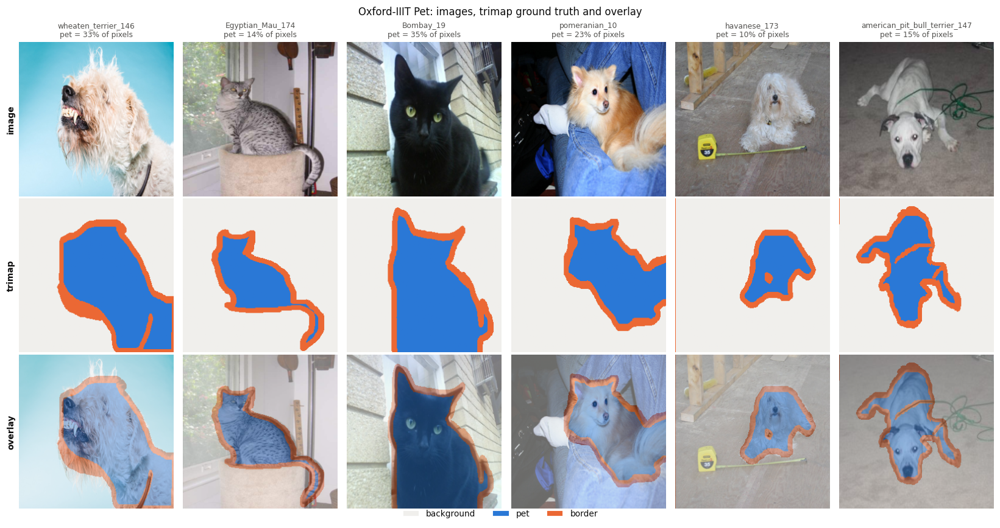

In [7]:
# ---------------------------------------------------- Figure: sample images + ground truth
set_seed(7)
idx = np.random.choice(CA["train"][0].shape[0], 6, replace=False)
fig, axes = plt.subplots(3, 6, figsize=(15, 7.8))
for c, i in enumerate(idx):
    im = np.asarray(CA["train"][0][i]); mk = np.asarray(CA["train"][1][i])
    axes[0, c].imshow(im)
    axes[1, c].imshow(colorize(mk))
    axes[2, c].imshow(im); axes[2, c].imshow(colorize(mk), alpha=0.45)
    axes[0, c].set_title(f"{SPLITS['train'][i][0]}\npet = {(mk==1).mean()*100:.0f}% of pixels",
                         fontsize=8, color=INK2, fontweight="normal")
    for r in range(3):
        no_axes(axes[r, c])
for r, lab in enumerate(["image", "trimap", "overlay"]):
    axes[r, 0].set_ylabel(lab, fontsize=9, color=INK, fontweight="bold")
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
    axes[r, 0].grid(False)
handles = [plt.Rectangle((0, 0), 1, 1, fc=MASK_COLORS[i], ec="white", lw=1.2) for i in range(3)]
fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.015))
fig.suptitle("Oxford-IIIT Pet: images, trimap ground truth and overlay", y=0.98)
fig.tight_layout()
savefig(fig, "fig01_dataset_samples")

  saved -> outputs/figures/fig02_dataset_stats.png


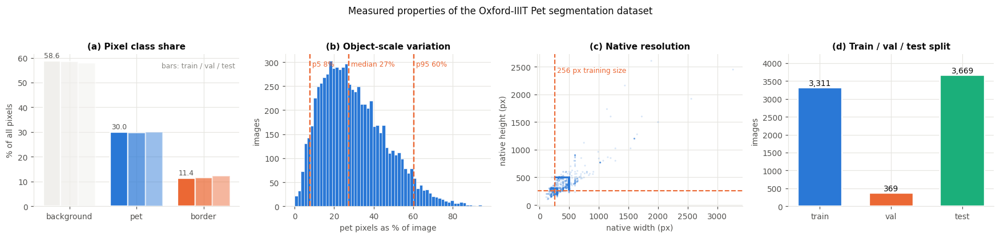

In [8]:
# ---------------------------------------------------- Figure: dataset statistics (4 panels)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))

# (a) pixel class share, per split -- grouped bars, identity colours = the mask colours
w = 0.26
xs = np.arange(3)
for j, k in enumerate(["train", "val", "test"]):
    ax[0].bar(xs + (j-1)*w, stats[k]["pixel_share"], w,
              color=[MASK_COLORS[i] for i in range(3)],
              alpha=[1.0, 0.72, 0.48][j], edgecolor="white", linewidth=1.5)
for i, v in enumerate(stats["train"]["pixel_share"]):
    ax[0].text(i-w, v+1.4, f"{v:.1f}", ha="center", fontsize=8, color=INK2)
ax[0].set_xticks(xs); ax[0].set_xticklabels(CLASS_NAMES)
ax[0].set_ylabel("% of all pixels"); ax[0].set_title("(a) Pixel class share")
ax[0].text(0.98, 0.95, "bars: train / val / test", transform=ax[0].transAxes,
           ha="right", va="top", fontsize=8, color=INK3)

# (b) foreground-fraction distribution -- the scale-variation evidence
ax[1].hist(allfg*100, bins=60, color=PALETTE[0], edgecolor="white", linewidth=0.4)
for q, lab in [(5, "p5"), (50, "median"), (95, "p95")]:
    v = np.percentile(allfg, q)*100
    ax[1].axvline(v, color=PALETTE[1], lw=1.6, ls="--")
    ax[1].text(v, ax[1].get_ylim()[1]*0.92, f" {lab} {v:.0f}%", fontsize=8, color=PALETTE[1])
ax[1].set_xlabel("pet pixels as % of image"); ax[1].set_ylabel("images")
ax[1].set_title("(b) Object-scale variation")

# (c) native resolution scatter
ax[2].scatter(allsz[:, 0], allsz[:, 1], s=4, alpha=0.18, color=PALETTE[0],
              edgecolors="none", rasterized=True)
ax[2].axvline(S, color=PALETTE[1], lw=1.4, ls="--")
ax[2].axhline(S, color=PALETTE[1], lw=1.4, ls="--")
ax[2].text(S+40, allsz[:, 1].max()*0.92, f"{S} px training size", fontsize=8, color=PALETTE[1])
ax[2].set_xlabel("native width (px)"); ax[2].set_ylabel("native height (px)")
ax[2].set_title("(c) Native resolution")

# (d) split sizes
ks = list(SPLITS); vs = [len(SPLITS[k]) for k in ks]
b = ax[3].bar(ks, vs, color=PALETTE[:3], edgecolor="white", linewidth=1.5, width=0.62)
for r, v in zip(b, vs):
    ax[3].text(r.get_x()+r.get_width()/2, v+60, f"{v:,}", ha="center", fontsize=9, color=INK)
ax[3].set_ylabel("images"); ax[3].set_title("(d) Train / val / test split")
ax[3].set_ylim(0, max(vs)*1.16)

fig.suptitle("Measured properties of the Oxford-IIIT Pet segmentation dataset", y=1.04)
fig.tight_layout()
savefig(fig, "fig02_dataset_stats")

## 2.3 Data augmentation and batching

Augmentation runs **on the GPU, on whole batches**, rather than in CPU `DataLoader` workers. Two
reasons: the GPU is so much faster than JPEG decoding that CPU-side augmentation would become the
bottleneck, and spawning workers from a notebook on Windows is fragile. Keeping the training
split resident in GPU memory as `uint8` removes the host-to-device copy entirely.

The policy --- identical for every model --- is:

| Transform | Range | Interpolation |
|---|---|---|
| Horizontal flip | p = 0.5 | — |
| Rotation | ±12° | image bilinear, **mask nearest** |
| Scale (zoom-in) | 1.00 – 1.25 | image bilinear, **mask nearest** |
| Translation | ±6% of side | image bilinear, **mask nearest** |
| Brightness / contrast / saturation | ±20% | image only |

Geometry is applied to image and mask with *the same* sampling grid so they stay registered;
photometric jitter touches the image only. Validation and test data receive **no** augmentation.

In [9]:
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
IMNET_STD  = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)

def to_float(img_u8):           # (B,H,W,3) uint8 -> (B,3,H,W) float in [0,1]
    return img_u8.permute(0, 3, 1, 2).float().div_(255.0)

def normalize(x):
    return (x - IMNET_MEAN) / IMNET_STD

def denormalize(x):
    return (x * IMNET_STD + IMNET_MEAN).clamp(0, 1)

def gpu_augment(img, msk):
    # img (B,3,H,W) float[0,1]; msk (B,1,H,W) float labels. Same grid for both.
    B = img.shape[0]; dev = img.device
    flip = (torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1)
    img = torch.where(flip, img.flip(-1), img)
    msk = torch.where(flip, msk.flip(-1), msk)

    ang = (torch.rand(B, device=dev) * 2 - 1) * (12 * math.pi / 180)
    sc  = 1.0 + torch.rand(B, device=dev) * 0.25
    tx  = (torch.rand(B, device=dev) * 2 - 1) * 0.06
    ty  = (torch.rand(B, device=dev) * 2 - 1) * 0.06
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0], theta[:, 0, 1], theta[:, 0, 2] = cos, -sin, tx
    theta[:, 1, 0], theta[:, 1, 1], theta[:, 1, 2] = sin,  cos, ty
    grid = F.affine_grid(theta, img.shape, align_corners=False)
    img = F.grid_sample(img, grid, mode="bilinear", padding_mode="border", align_corners=False)
    msk = F.grid_sample(msk, grid, mode="nearest",  padding_mode="border", align_corners=False)

    r = lambda a: 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * a
    img = img * r(0.2)                                             # brightness
    mu  = img.mean(dim=(1, 2, 3), keepdim=True)
    img = (img - mu) * r(0.2) + mu                                 # contrast
    gy  = img.mean(dim=1, keepdim=True)
    img = (img - gy) * r(0.2) + gy                                 # saturation
    return img.clamp(0, 1), msk

# training split lives on the GPU; val/test stream from RAM
TR_IMG = torch.from_numpy(np.ascontiguousarray(CA["train"][0])).to(DEV)
TR_MSK = torch.from_numpy(np.ascontiguousarray(CA["train"][1])).to(DEV)
print(f"train tensors on {DEV}: {TR_IMG.shape} + {TR_MSK.shape} "
      f"= {(TR_IMG.nbytes+TR_MSK.nbytes)/1e6:.0f} MB")

def train_batches(bs=None, augment=True):
    bs = bs or CFG.batch
    order = torch.randperm(TR_IMG.shape[0], device=DEV)
    for i in range(0, order.numel() - bs + 1, bs):            # drop_last
        j = order[i:i+bs]
        img = to_float(TR_IMG[j]); msk = TR_MSK[j].unsqueeze(1).float()
        if augment:
            img, msk = gpu_augment(img, msk)
        yield normalize(img), msk.squeeze(1).long()

def eval_batches(split, bs=32):
    img_np, msk_np, _ = CA[split]
    for i in range(0, img_np.shape[0], bs):
        img = torch.from_numpy(np.ascontiguousarray(img_np[i:i+bs])).to(DEV, non_blocking=True)
        msk = torch.from_numpy(np.ascontiguousarray(msk_np[i:i+bs])).to(DEV, non_blocking=True)
        yield normalize(to_float(img)), msk.long()

STEPS_PER_EPOCH = TR_IMG.shape[0] // CFG.batch
print(f"{STEPS_PER_EPOCH} iterations/epoch  x  {CFG.epochs} epochs "
      f"= {STEPS_PER_EPOCH*CFG.epochs:,} iterations per model")

train tensors on cuda: torch.Size([3311, 256, 256, 3]) + torch.Size([3311, 256, 256]) = 868 MB
206 iterations/epoch  x  30 epochs = 6,180 iterations per model


  saved -> outputs/figures/fig03_augmentation.png


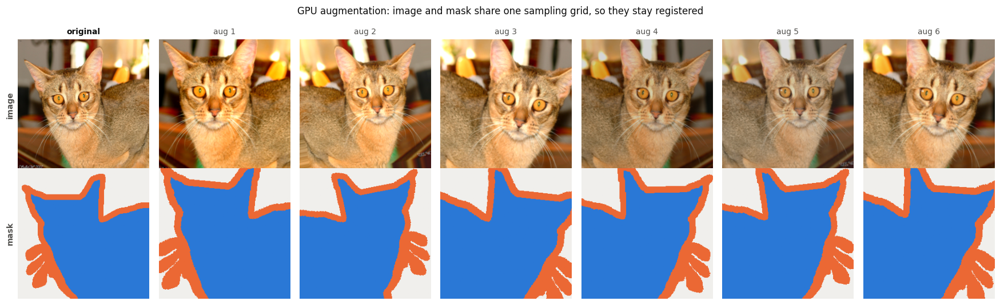

In [10]:
# ---------------------------------------------------- Figure: augmentation examples
set_seed(3)
img0 = to_float(TR_IMG[:1]).repeat(6, 1, 1, 1)
msk0 = TR_MSK[:1].unsqueeze(1).float().repeat(6, 1, 1, 1)
aimg, amsk = gpu_augment(img0.clone(), msk0.clone())
fig, axes = plt.subplots(2, 7, figsize=(16, 4.8))
axes[0, 0].imshow(img0[0].permute(1, 2, 0).cpu().numpy())
axes[1, 0].imshow(colorize(msk0[0, 0].cpu().numpy().astype(int)))
axes[0, 0].set_title("original", fontsize=9)
for c in range(6):
    axes[0, c+1].imshow(aimg[c].permute(1, 2, 0).cpu().numpy())
    axes[1, c+1].imshow(colorize(amsk[c, 0].cpu().numpy().astype(int)))
    axes[0, c+1].set_title(f"aug {c+1}", fontsize=9, color=INK2, fontweight="normal")
for a in axes.ravel():
    no_axes(a)
axes[0, 0].set_ylabel("image", fontweight="bold"); axes[1, 0].set_ylabel("mask", fontweight="bold")
for r in range(2):
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([]); axes[r, 0].grid(False)
fig.suptitle("GPU augmentation: image and mask share one sampling grid, so they stay registered", y=1.0)
fig.tight_layout()
savefig(fig, "fig03_augmentation")

## 2.4 Architectures

### The shared encoder

Every CNN model below is built on the same `ResNet34Encoder`, initialised from the same
ImageNet weights. For a 256x256 input it emits five feature maps:

| Tag | Source | Channels | Resolution | Stride |
|---|---|---|---|---|
| `c1` | stem conv | 64 | 128 x 128 | /2 |
| `c2` | `layer1` | 64 | 64 x 64 | /4 |
| `c3` | `layer2` | 128 | 32 x 32 | /8 |
| `c4` | `layer3` | 256 | 16 x 16 | /16 |
| `c5` | `layer4` | 512 | 8 x 8 | /32 |

Fixing this backbone is the core of the experimental design: whatever differences appear in the
results table, they come from how each decoder *recombines* these five maps, not from a stronger
or weaker feature extractor.

### A uniform output contract

Several of these architectures (U-Net++, BASNet, and the custom model in Task 3) use **deep
supervision** --- they attach loss terms to intermediate decoder outputs, not just the final one.
To keep training code uniform, **every** model's `forward` returns a *list* of logit tensors with
the main prediction first; models without deep supervision simply return a one-element list.
The loss function then weights element 0 fully and the rest by `CFG.deep_sup_w`.

In [11]:
# ======================================================================= shared pieces
def cbr(i, o, k=3, p=1, d=1):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=p, dilation=d, bias=False),
                         nn.BatchNorm2d(o), nn.ReLU(inplace=True))

def up2(x, ref=None):
    if ref is not None:
        return F.interpolate(x, size=ref.shape[-2:], mode="bilinear", align_corners=False)
    return F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)


def dilate_stage(layer, dilation=2):
    # torchvision's `replace_stride_with_dilation` only works for Bottleneck blocks, so
    # ResNet-34 (BasicBlock) has to be dilated by hand. We follow torchvision's own convention:
    # drop the stride on the first block and keep its dilation at 1, then dilate the rest.
    for i, blk in enumerate(layer):
        if i == 0:
            blk.conv1.stride = (1, 1)
            if blk.downsample is not None:
                blk.downsample[0].stride = (1, 1)
        else:
            for conv in (blk.conv1, blk.conv2):
                if conv.kernel_size == (3, 3):
                    conv.dilation = (dilation, dilation)
                    conv.padding  = (dilation, dilation)
    return layer


class ResNet34Encoder(nn.Module):
    # Shared ImageNet-pretrained backbone. output_stride=16 dilates layer4 (DeepLabV3+ only).
    def __init__(self, pretrained=True, output_stride=32):
        super().__init__()
        w = torchvision.models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else None
        net = torchvision.models.resnet34(weights=w)
        if output_stride == 16:
            dilate_stage(net.layer4, 2)
        self.stem   = nn.Sequential(net.conv1, net.bn1, net.relu)
        self.pool   = net.maxpool
        self.layer1, self.layer2 = net.layer1, net.layer2
        self.layer3, self.layer4 = net.layer3, net.layer4
        self.channels = [64, 64, 128, 256, 512]

    def forward(self, x):
        c1 = self.stem(x)                 # 64  /2
        c2 = self.layer1(self.pool(c1))   # 64  /4
        c3 = self.layer2(c2)              # 128 /8
        c4 = self.layer3(c3)              # 256 /16
        c5 = self.layer4(c4)              # 512 /32 (or /16 when dilated)
        return [c1, c2, c3, c4, c5]


class DecBlock(nn.Module):
    # upsample -> optional skip concat -> two 3x3 conv-BN-ReLU
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(cbr(in_ch + skip_ch, out_ch), cbr(out_ch, out_ch))

    def forward(self, x, skip=None):
        x = up2(x, skip)
        if skip is not None:
            x = torch.cat([x, skip], 1)
        return self.block(x)


class AttentionGate(nn.Module):
    # Additive attention gate (Oktay et al. 2018). `g` is the coarse decoder signal,
    # `x` the encoder skip; the gate suppresses skip regions the decoder is not attending to.
    def __init__(self, g_ch, x_ch, inter):
        super().__init__()
        self.Wg  = nn.Sequential(nn.Conv2d(g_ch, inter, 1, bias=False), nn.BatchNorm2d(inter))
        self.Wx  = nn.Sequential(nn.Conv2d(x_ch, inter, 1, bias=False), nn.BatchNorm2d(inter))
        self.psi = nn.Sequential(nn.Conv2d(inter, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())

    def forward(self, g, x):
        a = self.psi(F.relu(self.Wg(g) + self.Wx(x), inplace=True))
        return x * a, a


class ASPP(nn.Module):
    # Atrous Spatial Pyramid Pooling (DeepLab): parallel dilated convs + global image pooling.
    def __init__(self, in_ch, out_ch=256, rates=(6, 12, 18)):
        super().__init__()
        self.b0 = cbr(in_ch, out_ch, k=1, p=0)
        self.bs = nn.ModuleList([cbr(in_ch, out_ch, k=3, p=r, d=r) for r in rates])
        self.gp = nn.Sequential(nn.AdaptiveAvgPool2d(1),
                                nn.Conv2d(in_ch, out_ch, 1, bias=False),
                                nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
        self.proj = nn.Sequential(cbr(out_ch * (2 + len(rates)), out_ch, k=1, p=0), nn.Dropout2d(0.1))

    def forward(self, x):
        feats = [self.b0(x)] + [b(x) for b in self.bs]
        g = F.interpolate(self.gp(x), size=x.shape[-2:], mode="bilinear", align_corners=False)
        return self.proj(torch.cat(feats + [g], 1))

print("shared building blocks defined")

shared building blocks defined


### 1. U-Net

The reference encoder-decoder. Each decoder stage doubles the resolution and **concatenates the
encoder map of matching resolution** before two 3x3 convolutions. The skip connection is the whole
idea: the bottleneck knows *what* the object is but has thrown away *where* its edges are, and the
skip hands that spatial detail back. Everything that follows in this notebook is a variation on
this theme.

In [12]:
class UNet(nn.Module):
    def __init__(self, n_classes=3, pretrained=True):
        super().__init__()
        self.enc = ResNet34Encoder(pretrained)
        ch = self.enc.channels                      # [64,64,128,256,512]
        d  = [256, 128, 64, 32, 16]
        self.d4 = DecBlock(ch[4], ch[3], d[0])      # /32 -> /16
        self.d3 = DecBlock(d[0],  ch[2], d[1])      # /16 -> /8
        self.d2 = DecBlock(d[1],  ch[1], d[2])      # /8  -> /4
        self.d1 = DecBlock(d[2],  ch[0], d[3])      # /4  -> /2
        self.d0 = DecBlock(d[3],  0,     d[4])      # /2  -> /1
        self.head = nn.Conv2d(d[4], n_classes, 1)

    def forward(self, x):
        c1, c2, c3, c4, c5 = self.enc(x)
        y = self.d4(c5, c4); y = self.d3(y, c3); y = self.d2(y, c2)
        y = self.d1(y, c1);  y = self.d0(y)
        return [self.head(y)]
print("UNet ok")

UNet ok


### 2. U-Net++

U-Net's skip connection joins an encoder map to a decoder map of the same resolution but *very
different semantic depth* --- a shallow, high-resolution feature is concatenated with a feature
that has passed through the whole bottleneck. U-Net++ argues that this semantic gap is what hurts,
and fills it with a **dense grid of intermediate nodes**: node `X[i][j]` receives every earlier
node on its own row plus an upsampled node from the row below. The skip is no longer a wire, it is
a short convolutional path that gradually closes the gap. Deep supervision is attached to each
node of the top row.

In [13]:
class UNetPP(nn.Module):
    def __init__(self, n_classes=3, pretrained=True, deep_sup=True):
        super().__init__()
        self.enc = ResNet34Encoder(pretrained)
        ch = self.enc.channels                       # [64,64,128,256,512]
        f  = [32, 64, 128, 256]                      # node widths for rows 0..3
        self.deep_sup = deep_sup
        self.nodes = nn.ModuleDict()
        for i in range(4):                           # row
            for j in range(1, 5 - i):                # column
                below = f[i+1] if (i + 1) <= 3 and j - 1 >= 1 else ch[i+1]
                in_ch = ch[i] + f[i] * (j - 1) + below
                self.nodes[f"x{i}_{j}"] = nn.Sequential(cbr(in_ch, f[i]), cbr(f[i], f[i]))
        self.final = nn.Sequential(cbr(f[0], 16), nn.Conv2d(16, n_classes, 1))
        if deep_sup:
            self.aux = nn.ModuleList([nn.Conv2d(f[0], n_classes, 1) for _ in range(3)])

    def forward(self, x):
        c = self.enc(x)
        X = {(i, 0): c[i] for i in range(5)}
        for j in range(1, 5):
            for i in range(5 - j):
                prev = [X[(i, k)] for k in range(j)]
                below = up2(X[(i + 1, j - 1)], prev[0])
                X[(i, j)] = self.nodes[f"x{i}_{j}"](torch.cat(prev + [below], 1))
        out = [F.interpolate(self.final(X[(0, 4)]), size=x.shape[-2:],
                             mode="bilinear", align_corners=False)]
        if self.deep_sup and self.training:
            for k, j in enumerate([1, 2, 3]):
                out.append(F.interpolate(self.aux[k](X[(0, j)]), size=x.shape[-2:],
                                         mode="bilinear", align_corners=False))
        return out
print("UNetPP ok")

UNetPP ok


### 3. FPN-based segmenter

The Feature Pyramid Network replaces concatenation with **lateral 1x1 projections into a common
channel width followed by top-down addition**. Every pyramid level therefore carries the same
number of channels and a *mixture* of coarse semantics and fine detail. Each level is then decoded
to a common 1/4 resolution and the levels are **summed**, so predictions for a small object and a
large object are produced by the same head from differently-scaled evidence. That symmetry across
scales is the reason FPN is the natural answer when object size varies a lot.

In [14]:
class FPNSegBlock(nn.Module):
    # bring one pyramid level up to the common 1/4 resolution
    def __init__(self, in_ch, out_ch, n_up):
        super().__init__()
        layers = [cbr(in_ch, out_ch)]
        for k in range(n_up):
            if k > 0:
                layers.append(cbr(out_ch, out_ch))
            layers.append(nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class FPNSeg(nn.Module):
    def __init__(self, n_classes=3, pretrained=True, pyr=256, seg=128):
        super().__init__()
        self.enc = ResNet34Encoder(pretrained)
        ch = self.enc.channels
        self.lat = nn.ModuleList([nn.Conv2d(ch[i], pyr, 1) for i in (1, 2, 3, 4)])   # c2..c5
        self.smooth = nn.ModuleList([cbr(pyr, pyr) for _ in range(3)])
        self.segs = nn.ModuleList([FPNSegBlock(pyr, seg, n) for n in (3, 2, 1, 0)])  # p5..p2
        self.drop = nn.Dropout2d(0.1)
        self.head = nn.Sequential(cbr(seg, seg), nn.Conv2d(seg, n_classes, 1))

    def forward(self, x):
        c = self.enc(x)
        l2, l3, l4, l5 = [self.lat[i](c[i + 1]) for i in range(4)]
        p5 = l5
        p4 = self.smooth[0](l4 + up2(p5, l4))
        p3 = self.smooth[1](l3 + up2(p4, l3))
        p2 = self.smooth[2](l2 + up2(p3, l2))
        s = sum(seg(p) for seg, p in zip(self.segs, [p5, p4, p3, p2]))
        y = self.head(self.drop(s))
        return [F.interpolate(y, size=x.shape[-2:], mode="bilinear", align_corners=False)]
print("FPNSeg ok")

FPNSeg ok


### 4. Attention U-Net

U-Net copies the *entire* encoder map across the skip, including the large background regions the
decoder has no use for. Attention U-Net inserts an **additive attention gate** on each skip: the
coarse decoder signal and the fine encoder signal are projected to a shared space, added, squashed
to a single-channel map through a sigmoid, and that map re-weights the skip. Background features
are attenuated *before* they are concatenated. This is the targeted answer to images where most of
the frame is irrelevant.

The gate maps are kept so they can be visualised later --- being able to show *where* the network
attends is a large part of this architecture's appeal.

In [15]:
class AttUNet(nn.Module):
    def __init__(self, n_classes=3, pretrained=True):
        super().__init__()
        self.enc = ResNet34Encoder(pretrained)
        ch = self.enc.channels
        d  = [256, 128, 64, 32, 16]
        self.g4 = AttentionGate(ch[4], ch[3], ch[3] // 2)
        self.g3 = AttentionGate(d[0],  ch[2], ch[2] // 2)
        self.g2 = AttentionGate(d[1],  ch[1], ch[1] // 2)
        self.g1 = AttentionGate(d[2],  ch[0], ch[0] // 2)
        self.d4 = DecBlock(ch[4], ch[3], d[0])
        self.d3 = DecBlock(d[0],  ch[2], d[1])
        self.d2 = DecBlock(d[1],  ch[1], d[2])
        self.d1 = DecBlock(d[2],  ch[0], d[3])
        self.d0 = DecBlock(d[3],  0,     d[4])
        self.head = nn.Conv2d(d[4], n_classes, 1)
        self.last_attn = None

    def forward(self, x):
        c1, c2, c3, c4, c5 = self.enc(x)
        a = []
        s4, m4 = self.g4(up2(c5, c4), c4); y = self.d4(c5, s4); a.append(m4)
        s3, m3 = self.g3(up2(y,  c3), c3); y = self.d3(y,  s3); a.append(m3)
        s2, m2 = self.g2(up2(y,  c2), c2); y = self.d2(y,  s2); a.append(m2)
        s1, m1 = self.g1(up2(y,  c1), c1); y = self.d1(y,  s1); a.append(m1)
        y = self.d0(y)
        self.last_attn = a
        return [self.head(y)]
print("AttUNet ok")

AttUNet ok


### 5. BASNet

BASNet is built around the complaint that IoU-style losses are dominated by the object *interior*,
so networks get the blob right and the **boundary** wrong. Its answer has two halves:

* a **predict module** --- a deeply-supervised encoder-decoder that produces a coarse mask, with a
  loss attached at every decoder stage so gradient reaches the shallow, high-resolution layers
  directly;
* a **residual refinement module (RRM)** --- a small second encoder-decoder that does not predict
  the mask again but predicts a **residual** which is *added* to the coarse logits. Learning a
  correction is a much easier objective than re-learning the whole mask, and the correction
  concentrates exactly where the coarse mask is wrong, i.e. along edges.

Adaptation: the original RRM refines a 1-channel saliency map. Here it refines the 3-channel
class logits, since this is a 3-class problem rather than binary saliency. The hybrid
BCE+SSIM+IoU loss of the paper is replaced by this notebook's shared CE+Dice loss so that the
comparison stays fair --- the architecture is what is being tested, not the loss.

In [16]:
class RRM(nn.Module):
    # Residual refinement: 4-level encoder-decoder that outputs a correction to the coarse logits.
    def __init__(self, n_classes=3, w=64):
        super().__init__()
        self.inc  = cbr(n_classes, w)
        self.e1, self.e2, self.e3, self.e4 = cbr(w, w), cbr(w, w), cbr(w, w), cbr(w, w)
        self.bridge = cbr(w, w)
        self.d4, self.d3, self.d2, self.d1 = (cbr(2*w, w), cbr(2*w, w), cbr(2*w, w), cbr(2*w, w))
        self.out = nn.Conv2d(w, n_classes, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2, ceil_mode=True)

    def forward(self, coarse):
        h0 = self.inc(coarse)
        h1 = self.e1(h0);          p1 = self.pool(h1)
        h2 = self.e2(p1);          p2 = self.pool(h2)
        h3 = self.e3(p2);          p3 = self.pool(h3)
        h4 = self.e4(p3);          p4 = self.pool(h4)
        b  = self.bridge(p4)
        y  = self.d4(torch.cat([up2(b, h4), h4], 1))
        y  = self.d3(torch.cat([up2(y, h3), h3], 1))
        y  = self.d2(torch.cat([up2(y, h2), h2], 1))
        y  = self.d1(torch.cat([up2(y, h1), h1], 1))
        return coarse + self.out(y)          # residual, not a fresh prediction


class BASNet(nn.Module):
    def __init__(self, n_classes=3, pretrained=True, deep_sup=True):
        super().__init__()
        self.enc = ResNet34Encoder(pretrained)
        ch = self.enc.channels
        d  = [256, 128, 64, 32, 16]
        self.bridge = nn.Sequential(cbr(ch[4], 512, k=3, p=2, d=2), cbr(512, ch[4], k=3, p=2, d=2))
        self.d4 = DecBlock(ch[4], ch[3], d[0])
        self.d3 = DecBlock(d[0],  ch[2], d[1])
        self.d2 = DecBlock(d[1],  ch[1], d[2])
        self.d1 = DecBlock(d[2],  ch[0], d[3])
        self.d0 = DecBlock(d[3],  0,     d[4])
        self.head = nn.Conv2d(d[4], n_classes, 1)
        self.deep_sup = deep_sup
        self.side = nn.ModuleList([nn.Conv2d(c, n_classes, 3, padding=1)
                                   for c in [ch[4], d[0], d[1], d[2], d[3]]])
        self.rrm = RRM(n_classes)

    def forward(self, x):
        c1, c2, c3, c4, c5 = self.enc(x)
        b  = self.bridge(c5)
        y4 = self.d4(b,  c4); y3 = self.d3(y4, c3); y2 = self.d2(y3, c2)
        y1 = self.d1(y2, c1); y0 = self.d0(y1)
        coarse = self.head(y0)
        refined = self.rrm(coarse)                    # <- the model's prediction
        out = [refined]
        if self.training:
            out.append(coarse)                        # supervise the coarse map too
            if self.deep_sup:
                for s, f in zip(self.side, [b, y4, y3, y2, y1]):
                    out.append(F.interpolate(s(f), size=x.shape[-2:],
                                             mode="bilinear", align_corners=False))
        return out
print("BASNet ok")

BASNet ok


### 6. DeepLabV3+

DeepLab attacks the resolution problem from the opposite direction. Instead of recovering detail
through skips, it **refuses to throw it away**: the last residual stage is *dilated* rather than
strided, so the deepest features come out at stride 16 instead of 32. On top of them sits
**ASPP** --- parallel 3x3 convolutions at dilation 6, 12 and 18 plus a global image-pooling
branch. Those four branches look at the same point through four different receptive-field sizes,
and the global branch injects whole-image context. A deliberately light decoder then merges the
result with one low-level 1/4-resolution map.

This is the only model whose encoder differs, and the difference *is* the architecture: same
ResNet-34 weights, dilated final stage.

In [17]:
class DeepLabV3Plus(nn.Module):
    def __init__(self, n_classes=3, pretrained=True, low_ch=48, dec=256):
        super().__init__()
        self.enc = ResNet34Encoder(pretrained, output_stride=16)   # layer4 dilated
        ch = self.enc.channels
        self.aspp = ASPP(ch[4], dec, rates=(6, 12, 18))
        self.low  = cbr(ch[1], low_ch, k=1, p=0)                   # c2 @ /4
        self.dec  = nn.Sequential(cbr(dec + low_ch, dec), cbr(dec, dec), nn.Dropout2d(0.1))
        self.head = nn.Conv2d(dec, n_classes, 1)

    def forward(self, x):
        c = self.enc(x)
        a = self.aspp(c[4])
        a = F.interpolate(a, size=c[1].shape[-2:], mode="bilinear", align_corners=False)
        y = self.dec(torch.cat([a, self.low(c[1])], 1))
        return [F.interpolate(self.head(y), size=x.shape[-2:], mode="bilinear", align_corners=False)]
print("DeepLabV3Plus ok")

DeepLabV3Plus ok


### 7. SegFormer (MiT-B0)

The one non-convolutional entry. A hierarchical Mix-Transformer encoder produces features at
1/4, 1/8, 1/16 and 1/32, where **self-attention gives every token a global receptive field from
the very first stage** --- a convolutional network only reaches that after many layers of stacking.
The decoder is deliberately trivial: four linear projections to a common width, concatenate,
fuse with one MLP. SegFormer's claim is that if the encoder's context is good enough, the decoder
barely matters.

This is the deliberate exception to the shared-encoder rule, and the results table must be read
with that in mind: SegFormer-B0 has roughly a sixth of the parameters of the ResNet-34 models.

In [18]:
from transformers import SegformerForSemanticSegmentation

class SegFormer(nn.Module):
    def __init__(self, n_classes=3, pretrained=True, ckpt="nvidia/mit-b0"):
        super().__init__()
        self.net = SegformerForSemanticSegmentation.from_pretrained(
            ckpt, num_labels=n_classes, ignore_mismatched_sizes=True)

    def forward(self, x):
        y = self.net(pixel_values=x).logits               # emitted at 1/4 resolution
        return [F.interpolate(y, size=x.shape[-2:], mode="bilinear", align_corners=False)]
print("SegFormer ok")

SegFormer ok


### Model registry, capacity and cost

Before training anything, it is worth tabulating what each architecture actually costs. The cell
below counts parameters, estimates multiply-accumulate operations (MACs) for one 256x256 forward
pass by hooking every convolution and linear layer, and times inference. These columns are
referenced throughout the discussion: a model that wins by half a point of IoU while costing three
times the compute has not really won.

In [19]:
MODEL_ZOO = {
    "U-Net":           (UNet,           PALETTE[0]),
    "U-Net++":         (UNetPP,         PALETTE[1]),
    "FPN":             (FPNSeg,         PALETTE[2]),
    "Attention U-Net": (AttUNet,        PALETTE[3]),
    "BASNet":          (BASNet,         PALETTE[4]),
    "DeepLabV3+":      (DeepLabV3Plus,  PALETTE[5]),
    "SegFormer":       (SegFormer,      PALETTE[6]),
}
MODEL_COLOR = {k: v[1] for k, v in MODEL_ZOO.items()}

def build(name, pretrained=True):
    set_seed(CFG.seed)
    return MODEL_ZOO[name][0](n_classes=CFG.n_classes, pretrained=pretrained).to(DEV)

def count_macs(model, size=256):
    macs = [0]
    def hook(m, inp, out):
        if isinstance(m, nn.Conv2d):
            macs[0] += m.weight.numel() // m.groups * out.shape[-1] * out.shape[-2] * out.shape[0]
        elif isinstance(m, nn.Linear):
            macs[0] += m.weight.numel() * int(np.prod(out.shape[:-1]))
    hs = [m.register_forward_hook(hook) for m in model.modules()
          if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, size, size, device=DEV))
    for h in hs:
        h.remove()
    return macs[0]

def latency(model, size=256, n=30):
    model.eval(); x = torch.zeros(1, 3, size, size, device=DEV)
    with torch.no_grad():
        for _ in range(8):
            model(x)
        if DEV.type == "cuda":
            torch.cuda.synchronize()
        t = time.time()
        for _ in range(n):
            model(x)
        if DEV.type == "cuda":
            torch.cuda.synchronize()
    return (time.time() - t) / n * 1000

rows = []
for name in MODEL_ZOO:
    m = build(name)
    tot = sum(p.numel() for p in m.parameters())
    enc = sum(p.numel() for p in m.enc.parameters()) if hasattr(m, "enc") else float("nan")
    rows.append({"Model": name, "Params (M)": round(tot/1e6, 2),
                 "Encoder (M)": round(enc/1e6, 2) if enc == enc else None,
                 "Decoder (M)": round((tot-enc)/1e6, 2) if enc == enc else None,
                 "GMACs @256": round(count_macs(m)/1e9, 2),
                 "Latency (ms)": round(latency(m), 2)})
    del m; torch.cuda.empty_cache()

cap_df = pd.DataFrame(rows)
cap_df.to_csv(RES / "model_capacity.csv", index=False)
display(cap_df)

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b0 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


,Model,Params (M),Encoder (M),Decoder (M),GMACs @256,Latency (ms)
0,U-Net,24.44,21.28,3.15,7.81,4.05
1,U-Net++,25.77,21.28,4.49,13.01,5.17
2,FPN,25.07,21.28,3.79,10.63,4.57
3,Attention U-Net,24.57,21.28,3.29,7.95,5.49
4,BASNet,29.67,21.28,8.38,17.97,5.48
5,DeepLabV3+,26.71,21.28,5.43,13.63,4.16
6,SegFormer,3.71,NaN,NaN,1.66,7.02


  saved -> outputs/figures/fig04_model_capacity.png


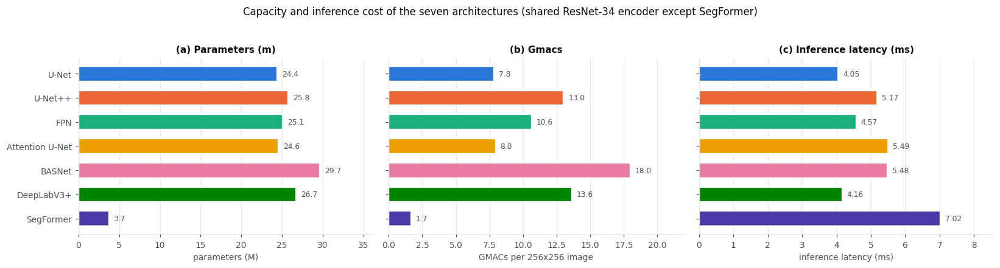

In [20]:
# ---------------------------------------------------- Figure: capacity vs cost
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
names = cap_df["Model"].tolist()
cols  = [MODEL_COLOR[n] for n in names]
y = np.arange(len(names))[::-1]

for k, (col, lab, fmt) in enumerate([("Params (M)", "parameters (M)", "{:.1f}"),
                                     ("GMACs @256", "GMACs per 256x256 image", "{:.1f}"),
                                     ("Latency (ms)", "inference latency (ms)", "{:.2f}")]):
    v = cap_df[col].values
    ax[k].barh(y, v, color=cols, height=0.62, edgecolor="white", linewidth=1.5)
    for yy, vv in zip(y, v):
        ax[k].text(vv + max(v)*0.02, yy, fmt.format(vv), va="center", fontsize=8, color=INK2)
    ax[k].set_yticks(y); ax[k].set_yticklabels(names if k == 0 else [])
    ax[k].set_xlabel(lab); ax[k].set_xlim(0, max(v)*1.22)
    ax[k].grid(axis="y", visible=False)
    ax[k].set_title("abc"[k].join(["(", ") "]) + lab.split(" per ")[0].capitalize())

fig.suptitle("Capacity and inference cost of the seven architectures (shared ResNet-34 encoder except SegFormer)", y=1.04)
fig.tight_layout()
savefig(fig, "fig04_model_capacity")

## 2.5 Loss function and evaluation metrics

### Loss

Every model is trained with the same objective:

$$\mathcal{L} \;=\; \underbrace{\mathrm{CE}(\hat{y}, y)}_{\text{per-pixel}} \;+\; \lambda_{\text{dice}}\Bigl(1 - \tfrac{1}{C}\sum_{c}\tfrac{2\sum p_c t_c + \epsilon}{\sum p_c + \sum t_c + \epsilon}\Bigr) \;+\; \lambda_{\text{ds}}\cdot\frac{1}{K}\sum_{k=1}^{K}\mathcal{L}_{\text{aux}}^{(k)}$$

Cross-entropy alone is a poor fit here: 61% of all pixels are background, so a network can reach
high loss-minimising accuracy while ignoring the thin border class entirely. The **Dice** term is
computed per class and averaged, which makes the 11% border class contribute as much to the
gradient as the 61% background class. The third term carries the deep-supervision auxiliaries and
is simply zero for the models that do not emit any.

### Metrics

All seven required metrics come from a **single accumulated 3x3 confusion matrix** over the test
set, which guarantees they are mutually consistent (computing them per-batch and averaging would
silently weight small batches wrongly). With `TP_c`, `FP_c`, `FN_c` read off that matrix:

| Metric | Definition | Reported as |
|---|---|---|
| IoU | `TP / (TP + FP + FN)` | **pet** class |
| Dice | `2TP / (2TP + FP + FN)` | **pet** class |
| Pixel Accuracy | `trace / total` | all pixels |
| Precision | `TP / (TP + FP)` | **pet** class |
| Recall | `TP / (TP + FN)` | **pet** class |
| F1 | harmonic mean of the two | **pet** class |
| Mean IoU | mean of per-class IoU | **all 3 classes** |

"IoU" and "Mean IoU" are listed separately in the assignment, so they are read as the
foreground-class IoU and the macro average across all three classes respectively. Macro averages
of the other metrics are also stored, and the full per-class breakdown is written to CSV.

In [21]:
def soft_dice_loss(logits, target, eps=1.0):
    p = logits.softmax(1)
    t = F.one_hot(target, CFG.n_classes).permute(0, 3, 1, 2).float()
    dims = (0, 2, 3)
    inter = (p * t).sum(dims)
    card  = p.sum(dims) + t.sum(dims)
    return 1.0 - ((2 * inter + eps) / (card + eps)).mean()


def boundary_band(target, k=5):
    # 1 where the label is not locally constant, i.e. within k/2 px of any class transition.
    t  = target.unsqueeze(1).float()
    mx =  F.max_pool2d(t,  k, 1, k // 2)
    mn = -F.max_pool2d(-t, k, 1, k // 2)
    return (mx != mn).float().squeeze(1)


class SegLoss(nn.Module):
    # CE + Dice, optional boundary re-weighting, optional deep supervision.
    def __init__(self, dice_w=CFG.dice_w, deep_sup_w=CFG.deep_sup_w, boundary_w=0.0):
        super().__init__()
        self.dice_w, self.deep_sup_w, self.boundary_w = dice_w, deep_sup_w, boundary_w

    def one(self, logits, target, band):
        ce = F.cross_entropy(logits, target, reduction="none")
        if self.boundary_w > 0 and band is not None:
            ce = ce * (1.0 + self.boundary_w * band)
        return ce.mean() + self.dice_w * soft_dice_loss(logits, target)

    def forward(self, outs, target):
        band = boundary_band(target) if self.boundary_w > 0 else None
        loss = self.one(outs[0], target, band)
        if len(outs) > 1:
            aux = sum(self.one(o, target, band) for o in outs[1:]) / (len(outs) - 1)
            loss = loss + self.deep_sup_w * aux
        return loss


class ConfMat:
    # rows = ground truth, cols = prediction
    def __init__(self, n=CFG.n_classes):
        self.n = n
        self.m = torch.zeros(n * n, dtype=torch.long, device=DEV)

    def update(self, pred, targ):
        self.m += torch.bincount((targ.reshape(-1) * self.n + pred.reshape(-1)),
                                 minlength=self.n * self.n)

    @property
    def mat(self):
        return self.m.view(self.n, self.n).double().cpu().numpy()


def metrics_from_cm(cm):
    m   = cm.mat if isinstance(cm, ConfMat) else np.asarray(cm, dtype=np.float64)
    tp  = np.diag(m)
    fp  = m.sum(0) - tp
    fn  = m.sum(1) - tp
    eps = 1e-9
    iou  = tp / (tp + fp + fn + eps)
    dice = 2 * tp / (2 * tp + fp + fn + eps)
    prec = tp / (tp + fp + eps)
    rec  = tp / (tp + fn + eps)
    f1   = 2 * prec * rec / (prec + rec + eps)
    out = {
        "IoU":            float(iou[FG]),
        "Dice":           float(dice[FG]),
        "Pixel Acc":      float(tp.sum() / (m.sum() + eps)),
        "Precision":      float(prec[FG]),
        "Recall":         float(rec[FG]),
        "F1":             float(f1[FG]),
        "Mean IoU":       float(iou.mean()),
        "Mean Dice":      float(dice.mean()),
        "Macro Precision": float(prec.mean()),
        "Macro Recall":    float(rec.mean()),
        "Macro F1":        float(f1.mean()),
    }
    for i, c in enumerate(CLASS_NAMES):
        out[f"IoU[{c}]"]  = float(iou[i])
        out[f"Dice[{c}]"] = float(dice[i])
    out["_cm"] = m
    return out

HEADLINE = ["IoU", "Dice", "Pixel Acc", "Precision", "Recall", "F1", "Mean IoU"]
CRITERION = SegLoss()
print("loss and metrics ready")

loss and metrics ready


## 2.6 Training

Identical protocol for every model. The only thing that changes between runs is the architecture
being instantiated.

| Setting | Value |
|---|---|
| Optimiser | AdamW |
| Learning rate | 3e-4, cosine-annealed to ~0 over all iterations |
| Weight decay | 1e-4 |
| Epochs | 30 |
| Batch size | 16 |
| Mixed precision | enabled (fp16 autocast + GradScaler) |
| Gradient clipping | global norm 1.0 |
| Model selection | checkpoint with the best **validation mean IoU** |
| Seed | 42, reset immediately before each build |

Checkpoints and per-epoch histories are written to disk, so re-running the notebook reloads
finished models instead of retraining them. Set `FORCE_RETRAIN = True` to override.

In [22]:
FORCE_RETRAIN = False

def tag_of(name):
    return (name.lower().replace(" ", "_").replace("+", "p")
                .replace("(", "").replace(")", "").replace("-", "_"))

@torch.no_grad()
def evaluate(model, split, bs=32, criterion=None):
    model.eval()
    cm, tot, n = ConfMat(), 0.0, 0
    for x, y in eval_batches(split, bs):
        with torch.amp.autocast("cuda", enabled=CFG.amp and DEV.type == "cuda"):
            outs = model(x)
            if criterion is not None:
                tot += float(criterion(outs, y)) * x.shape[0]
        cm.update(outs[0].float().argmax(1), y)
        n += x.shape[0]
    return metrics_from_cm(cm), (tot / max(n, 1))


def train_model(name, criterion=None, epochs=None, model=None, tag=None, verbose=True):
    tag = tag or tag_of(name)
    epochs = epochs or CFG.epochs
    criterion = criterion or CRITERION
    ck, hp = CKPT / f"{tag}.pt", RES / f"hist_{tag}.json"

    if ck.exists() and hp.exists() and not FORCE_RETRAIN:
        print(f"[{name}] checkpoint found -> skipping training")
        return json.loads(hp.read_text())

    model = model if model is not None else build(name)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    total = STEPS_PER_EPOCH * epochs
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total)
    scaler = torch.amp.GradScaler("cuda", enabled=CFG.amp and DEV.type == "cuda")

    hist = {"model": name, "tag": tag, "epochs": epochs,
            "train_loss": [], "val_loss": [], "val_miou": [], "val_iou": [], "lr": [], "epoch_s": []}
    best, t_start = -1.0, time.time()
    set_seed(CFG.seed)

    for ep in range(1, epochs + 1):
        model.train(); run, seen, t0 = 0.0, 0, time.time()
        bar = tqdm(train_batches(), total=STEPS_PER_EPOCH,
                   desc=f"{name} ep{ep:02d}/{epochs}", leave=False,
                   mininterval=5.0, ncols=78)
        for x, y in bar:
            with torch.amp.autocast("cuda", enabled=CFG.amp and DEV.type == "cuda"):
                loss = criterion(model(x), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += float(loss) * x.shape[0]; seen += x.shape[0]
            bar.set_postfix(loss=f"{run/seen:.4f}")

        vm, vl = evaluate(model, "val", criterion=criterion)
        hist["train_loss"].append(run / seen); hist["val_loss"].append(vl)
        hist["val_miou"].append(vm["Mean IoU"]); hist["val_iou"].append(vm["IoU"])
        hist["lr"].append(sched.get_last_lr()[0]); hist["epoch_s"].append(time.time() - t0)

        if vm["Mean IoU"] > best:
            best = vm["Mean IoU"]
            torch.save({"state_dict": model.state_dict(), "epoch": ep, "val_miou": best}, ck)
        if verbose and (ep % 5 == 0 or ep == 1 or ep == epochs):
            print(f"  [{name}] ep {ep:02d}  train {run/seen:.4f}  val {vl:.4f}  "
                  f"mIoU {vm['Mean IoU']:.4f}  petIoU {vm['IoU']:.4f}  ({time.time()-t0:.0f}s)")

    hist["best_val_miou"] = best
    hist["total_min"] = (time.time() - t_start) / 60
    hp.write_text(json.dumps(hist, indent=1))
    print(f"[{name}] done: best val mIoU {best:.4f} in {hist['total_min']:.1f} min")
    del model; torch.cuda.empty_cache()
    return hist


def load_trained(name, tag=None, model=None):
    tag = tag or tag_of(name)
    model = model if model is not None else build(name, pretrained=False)
    sd = torch.load(CKPT / f"{tag}.pt", map_location=DEV)
    model.load_state_dict(sd["state_dict"])
    return model.to(DEV).eval()

print(f"training protocol ready | {STEPS_PER_EPOCH} iters/epoch x {CFG.epochs} epochs")

training protocol ready | 206 iters/epoch x 30 epochs


In [23]:
HISTORIES = {}
for name in MODEL_ZOO:
    HISTORIES[name] = train_model(name)
print("\nall seven models trained.")

[U-Net] checkpoint found -> skipping training
[U-Net++] checkpoint found -> skipping training
[FPN] checkpoint found -> skipping training
[Attention U-Net] checkpoint found -> skipping training
[BASNet] checkpoint found -> skipping training
[DeepLabV3+] checkpoint found -> skipping training
[SegFormer] checkpoint found -> skipping training

all seven models trained.


  saved -> outputs/figures/fig05_training_curves.png


,Model,Best val mIoU,Best epoch,Epochs to 95% of best,Final train loss,Final val loss,Overfit gap,s / epoch,Total min
0,U-Net,0.8132,24,5,0.1721,0.2473,0.0752,8.9,4.5
1,U-Net++,0.8172,25,5,0.2996,0.2451,-0.0545,13.5,6.8
2,FPN,0.8160,23,3,0.1609,0.2498,0.0889,8.8,4.4
3,Attention U-Net,0.8134,28,6,0.1706,0.2505,0.0799,10.4,5.2
4,BASNet,0.8178,25,6,0.2415,0.2455,0.0040,20.6,10.3
5,DeepLabV3+,0.8145,23,4,0.1593,0.2519,0.0925,8.2,4.1
6,SegFormer,0.8109,30,3,0.1922,0.2547,0.0625,8.1,4.0


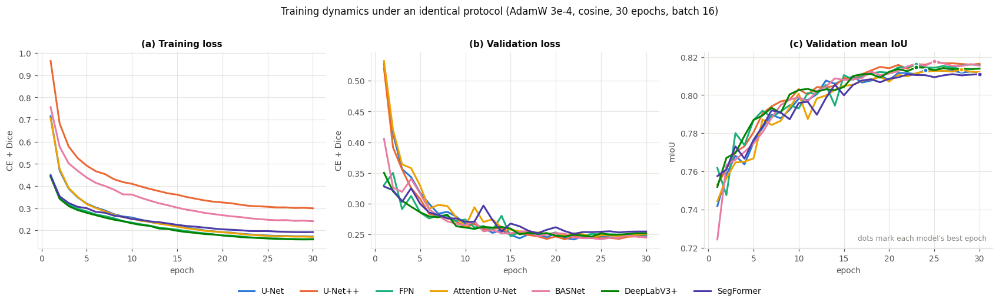

In [24]:
# ---------------------------------------------------- Figure: training curves
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.2))
for name, h in HISTORIES.items():
    e = np.arange(1, len(h["train_loss"]) + 1)
    c = MODEL_COLOR[name]
    ax[0].plot(e, h["train_loss"], color=c, label=name)
    ax[1].plot(e, h["val_loss"],   color=c, label=name)
    ax[2].plot(e, h["val_miou"],   color=c, label=name)
    ax[2].scatter([int(np.argmax(h["val_miou"]))+1], [max(h["val_miou"])],
                  color=c, s=26, zorder=5, edgecolor="white", linewidth=1.2)

ax[0].set_title("(a) Training loss");   ax[0].set_xlabel("epoch"); ax[0].set_ylabel("CE + Dice")
ax[1].set_title("(b) Validation loss"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("CE + Dice")
ax[2].set_title("(c) Validation mean IoU"); ax[2].set_xlabel("epoch"); ax[2].set_ylabel("mIoU")
ax[2].text(0.98, 0.04, "dots mark each model's best epoch", transform=ax[2].transAxes,
           ha="right", fontsize=8, color=INK3)
h_, l_ = ax[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=7, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Training dynamics under an identical protocol (AdamW 3e-4, cosine, 30 epochs, batch 16)", y=1.02)
fig.tight_layout()
savefig(fig, "fig05_training_curves")

conv = pd.DataFrame([{
    "Model": n,
    "Best val mIoU": round(max(h["val_miou"]), 4),
    "Best epoch": int(np.argmax(h["val_miou"])) + 1,
    "Epochs to 95% of best": int(np.argmax(np.array(h["val_miou"]) >= 0.95*max(h["val_miou"]))) + 1,
    "Final train loss": round(h["train_loss"][-1], 4),
    "Final val loss": round(h["val_loss"][-1], 4),
    "Overfit gap": round(h["val_loss"][-1] - h["train_loss"][-1], 4),
    "s / epoch": round(float(np.mean(h["epoch_s"])), 1),
    "Total min": round(h["total_min"], 1),
} for n, h in HISTORIES.items()])
conv.to_csv(RES / "convergence.csv", index=False)
display(conv)

## 2.7 Test-set evaluation

Each model is reloaded from its best-validation checkpoint and run once over the full
**3,669-image test set**. Alongside the global confusion matrix the loop records a **per-image**
pet IoU, which later lets us ask *which kinds of images* a model fails on rather than only
*how often* it fails.

In [25]:
# pick representative test images spanning the object-scale range, for the qualitative figure
test_fg = (np.asarray(CA["test"][1]) == 1).reshape(CA["test"][1].shape[0], -1).mean(1)
SHOW_IDX = [int(np.argsort(test_fg)[int(q * (len(test_fg) - 1))]) for q in (0.04, 0.25, 0.5, 0.78, 0.96)]
print("qualitative sample indices (by pet-pixel fraction):")
for i in SHOW_IDX:
    print(f"  idx {i:5d}  {SPLITS['test'][i][0]:28s}  pet = {test_fg[i]*100:5.1f}%")


@torch.no_grad()
def test_full(model, bs=32, keep=SHOW_IDX):
    model.eval()
    cm = ConfMat()
    per_img, kept, base = [], {}, 0
    for x, y in eval_batches("test", bs):
        with torch.amp.autocast("cuda", enabled=CFG.amp and DEV.type == "cuda"):
            logits = model(x)[0].float()
        pred = logits.argmax(1)
        cm.update(pred, y)
        p1, t1 = (pred == FG), (y == FG)
        inter = (p1 & t1).sum((1, 2)).double()
        union = (p1 | t1).sum((1, 2)).double()
        per_img.append(((inter + 1e-9) / (union + 1e-9)).cpu().numpy())
        for k in keep:
            if base <= k < base + x.shape[0]:
                kept[k] = pred[k - base].cpu().numpy().astype(np.uint8)
        base += x.shape[0]
    return metrics_from_cm(cm), np.concatenate(per_img), kept


RESULTS, PERIMG, QUAL = {}, {}, {}
for name in MODEL_ZOO:
    m = load_trained(name)
    met, pim, kept = test_full(m)
    RESULTS[name], PERIMG[name], QUAL[name] = met, pim, kept
    print(f"{name:17s} IoU {met['IoU']:.4f}  Dice {met['Dice']:.4f}  "
          f"PixAcc {met['Pixel Acc']:.4f}  mIoU {met['Mean IoU']:.4f}")
    del m; torch.cuda.empty_cache()

qualitative sample indices (by pet-pixel fraction):
  idx  1313  english_setter_38             pet =   6.4%
  idx  1221  english_cocker_spaniel_45     pet =  16.9%
  idx  1407  german_shorthaired_32         pet =  27.1%
  idx  1994  Maine_Coon_249                pet =  42.8%
  idx    45  Abyssinian_49                 pet =  63.8%


U-Net             IoU 0.8911  Dice 0.9424  PixAcc 0.9381  mIoU 0.8211


U-Net++           IoU 0.8922  Dice 0.9430  PixAcc 0.9386  mIoU 0.8222


FPN               IoU 0.8924  Dice 0.9431  PixAcc 0.9391  mIoU 0.8241


Attention U-Net   IoU 0.8940  Dice 0.9440  PixAcc 0.9390  mIoU 0.8208


BASNet            IoU 0.8941  Dice 0.9441  PixAcc 0.9392  mIoU 0.8230


DeepLabV3+        IoU 0.8910  Dice 0.9423  PixAcc 0.9377  mIoU 0.8190


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b0 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


SegFormer         IoU 0.8913  Dice 0.9426  PixAcc 0.9378  mIoU 0.8191


## 2.8 Comparative results

The table the assignment asks for. `IoU`, `Dice`, `Precision`, `Recall` and `F1` are for the
**pet** class; `Pixel Acc` is over all pixels; `Mean IoU` averages over background, pet and border.

In [26]:
def results_table(res_dict, order=None):
    order = order or list(res_dict)
    df = pd.DataFrame([{"Model": n, **{k: round(res_dict[n][k], 4) for k in HEADLINE}}
                       for n in order])
    return df

res_df = results_table(RESULTS)
res_df.to_csv(RES / "task2_results.csv", index=False)
display(res_df.style.format({c: "{:.4f}" for c in HEADLINE})
        .background_gradient(cmap=SEQ_BLUE, subset=HEADLINE, axis=0))

# full per-class breakdown
per_class = pd.DataFrame([{"Model": n,
                           **{f"IoU {c}": round(RESULTS[n][f"IoU[{c}]"], 4) for c in CLASS_NAMES},
                           **{f"Dice {c}": round(RESULTS[n][f"Dice[{c}]"], 4) for c in CLASS_NAMES},
                           "Mean Dice": round(RESULTS[n]["Mean Dice"], 4),
                           "Macro F1": round(RESULTS[n]["Macro F1"], 4)}
                          for n in MODEL_ZOO])
per_class.to_csv(RES / "task2_per_class.csv", index=False)
display(per_class)

,Model,IoU,Dice,Pixel Acc,Precision,Recall,F1,Mean IoU
0,U-Net,0.8911,0.9424,0.9381,0.9387,0.9462,0.9424,0.8211
1,U-Net++,0.8922,0.9430,0.9386,0.9403,0.9458,0.9430,0.8222
2,FPN,0.8924,0.9431,0.9391,0.9422,0.9441,0.9431,0.8241
3,Attention U-Net,0.8940,0.9440,0.9390,0.9381,0.9500,0.9440,0.8208
4,BASNet,0.8941,0.9441,0.9392,0.9405,0.9477,0.9441,0.8230
5,DeepLabV3+,0.8910,0.9423,0.9377,0.9384,0.9463,0.9423,0.8190
6,SegFormer,0.8913,0.9426,0.9378,0.9366,0.9486,0.9426,0.8191


,Model,IoU background,IoU pet,IoU border,Dice background,Dice pet,Dice border,Mean Dice,Macro F1
0,U-Net,0.9427,0.8911,0.6294,0.9705,0.9424,0.7726,0.8952,0.8952
1,U-Net++,0.9431,0.8922,0.6312,0.9707,0.9430,0.7739,0.8959,0.8959
2,FPN,0.9436,0.8924,0.6363,0.9710,0.9431,0.7777,0.8973,0.8973
3,Attention U-Net,0.9432,0.8940,0.6253,0.9708,0.9440,0.7695,0.8947,0.8947
4,BASNet,0.9437,0.8941,0.6311,0.9711,0.9441,0.7738,0.8963,0.8963
5,DeepLabV3+,0.9425,0.8910,0.6234,0.9704,0.9423,0.7680,0.8936,0.8936
6,SegFormer,0.9433,0.8913,0.6226,0.9708,0.9426,0.7674,0.8936,0.8936


  saved -> outputs/figures/fig06_metric_comparison.png


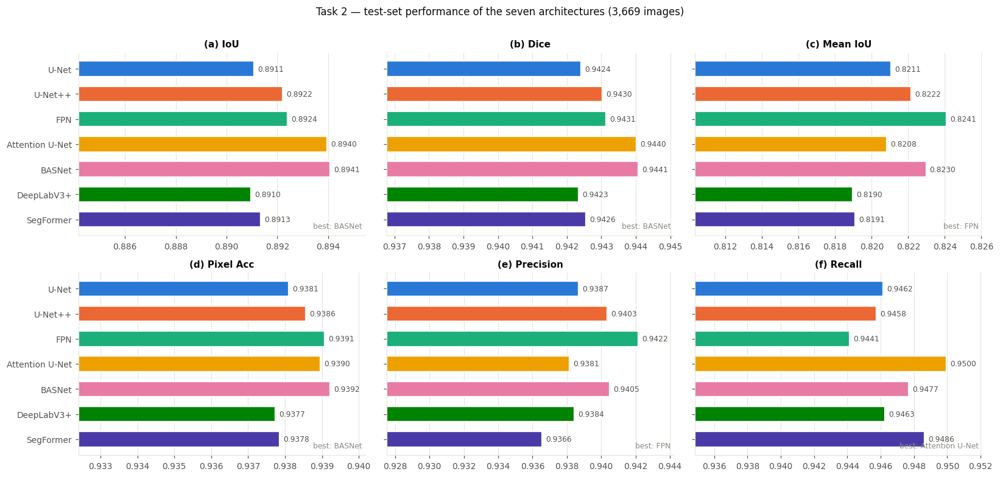

In [27]:
# ---------------------------------------------------- Figure: headline metric comparison
names = list(RESULTS)
show  = ["IoU", "Dice", "Mean IoU", "Pixel Acc", "Precision", "Recall"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for k, met in enumerate(show):
    ax = axes[k // 3, k % 3]
    v = np.array([RESULTS[n][met] for n in names])
    y = np.arange(len(names))[::-1]
    ax.barh(y, v, color=[MODEL_COLOR[n] for n in names], height=0.62,
            edgecolor="white", linewidth=1.5)
    lo = max(0.0, v.min() - (v.max() - v.min()) * 0.9 - 0.004)
    ax.set_xlim(lo, v.max() + (v.max() - lo) * 0.14)
    for yy, vv in zip(y, v):
        ax.text(vv + (v.max() - lo) * 0.015, yy, f"{vv:.4f}", va="center",
                fontsize=8, color=INK2)
    best = int(np.argmax(v))
    ax.text(0.99, 0.04, f"best: {names[best]}", transform=ax.transAxes, ha="right",
            fontsize=8, color=INK3)
    ax.set_yticks(y); ax.set_yticklabels(names if k % 3 == 0 else [])
    ax.set_title(f"({'abcdef'[k]}) {met}"); ax.grid(axis="y", visible=False)
fig.suptitle("Task 2 — test-set performance of the seven architectures (3,669 images)", y=1.01)
fig.tight_layout()
savefig(fig, "fig06_metric_comparison")

  saved -> outputs/figures/fig07_confusion_matrices.png


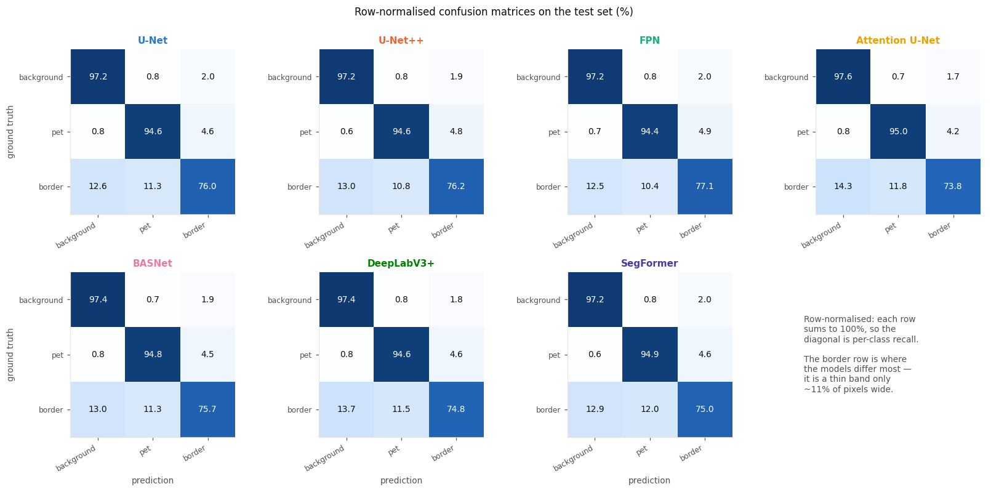

In [28]:
# ---------------------------------------------------- Figure: confusion matrices
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2))
for k, name in enumerate(names):
    ax = axes[k // 4, k % 4]
    cm = RESULTS[name]["_cm"]
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap=SEQ_BLUE, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cmn[i,j]*100:.1f}", ha="center", va="center", fontsize=9,
                    color="white" if cmn[i, j] > 0.55 else INK)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_title(name, color=MODEL_COLOR[name]); ax.grid(False)
    if k % 4 == 0:
        ax.set_ylabel("ground truth")
    if k // 4 == 1:
        ax.set_xlabel("prediction")
axes[1, 3].axis("off")
axes[1, 3].text(0.0, 0.5, "Row-normalised: each row\nsums to 100%, so the\ndiagonal is per-class recall.\n\n"
                "The border row is where\nthe models differ most —\nit is a thin band only\n"
                "~11% of pixels wide.", fontsize=9, color=INK2, va="center")
fig.suptitle("Row-normalised confusion matrices on the test set (%)", y=1.0)
fig.tight_layout()
savefig(fig, "fig07_confusion_matrices")

  saved -> outputs/figures/fig08_qualitative.png


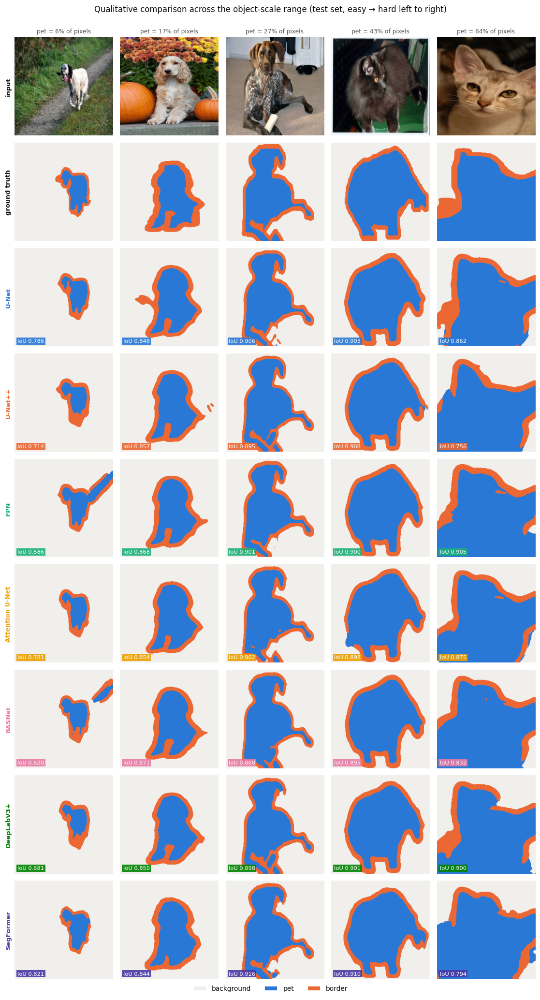

In [29]:
# ---------------------------------------------------- Figure: qualitative predictions
rows = 2 + len(names)
fig, axes = plt.subplots(len(names) + 2, len(SHOW_IDX), figsize=(2.05*len(SHOW_IDX), 2.05*(len(names)+2)))
for c, i in enumerate(SHOW_IDX):
    im = np.asarray(CA["test"][0][i]); gt = np.asarray(CA["test"][1][i])
    axes[0, c].imshow(im)
    axes[0, c].set_title(f"pet = {test_fg[i]*100:.0f}% of pixels", fontsize=8,
                         color=INK2, fontweight="normal")
    axes[1, c].imshow(colorize(gt))
    for r, name in enumerate(names):
        pr = QUAL[name][i]
        axes[r+2, c].imshow(colorize(pr))
        iou = ((pr == FG) & (gt == FG)).sum() / max(((pr == FG) | (gt == FG)).sum(), 1)
        axes[r+2, c].text(0.03, 0.04, f"IoU {iou:.3f}", transform=axes[r+2, c].transAxes,
                          fontsize=7.5, color="white",
                          bbox=dict(fc=MODEL_COLOR[name], ec="none", pad=1.6, alpha=0.9))
    for r in range(rows):
        no_axes(axes[r, c])
for r, lab in enumerate(["input", "ground truth"] + names):
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([]); axes[r, 0].grid(False)
    axes[r, 0].set_ylabel(lab, fontsize=8.5, fontweight="bold",
                          color=MODEL_COLOR.get(lab, INK))
handles = [plt.Rectangle((0, 0), 1, 1, fc=MASK_COLORS[i], ec="white", lw=1.2) for i in range(3)]
fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.012))
fig.suptitle("Qualitative comparison across the object-scale range (test set, easy → hard left to right)", y=1.0)
fig.tight_layout()
savefig(fig, "fig08_qualitative")

  saved -> outputs/figures/fig09_diagnostics.png


,Model,<8%,8-16%,16-26%,26-40%,>40%,worst-best gap
0,U-Net,0.7196,0.8340,0.8742,0.8965,0.9220,0.2024
1,U-Net++,0.7082,0.8381,0.8739,0.8980,0.9233,0.2151
2,FPN,0.7247,0.8367,0.8741,0.8979,0.9234,0.1987
3,Attention U-Net,0.7211,0.8375,0.8759,0.8981,0.9250,0.2039
4,BASNet,0.7153,0.8373,0.8750,0.8993,0.9244,0.2091
5,DeepLabV3+,0.7133,0.8327,0.8718,0.8949,0.9236,0.2103
6,SegFormer,0.7045,0.8292,0.8713,0.8954,0.9259,0.2214


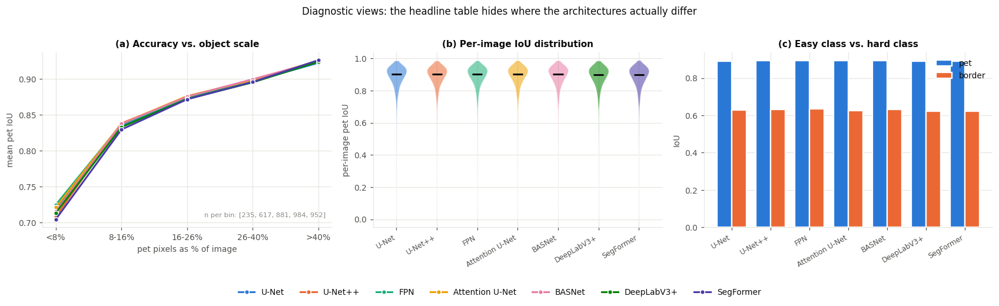

In [30]:
# ---------------------------------------------------- Figure: where the models differ
# (a) IoU as a function of object size  (b) per-image IoU distribution  (c) border-class IoU
bins   = [0.0, 0.08, 0.16, 0.26, 0.40, 1.01]
labels = ["<8%", "8-16%", "16-26%", "26-40%", ">40%"]
digit  = np.digitize(test_fg, bins) - 1

fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.1))
for name in names:
    y = [PERIMG[name][digit == b].mean() for b in range(len(labels))]
    ax[0].plot(range(len(labels)), y, marker="o", markersize=5, color=MODEL_COLOR[name],
               label=name, markeredgecolor="white", markeredgewidth=1.0)
ax[0].set_xticks(range(len(labels))); ax[0].set_xticklabels(labels)
ax[0].set_xlabel("pet pixels as % of image"); ax[0].set_ylabel("mean pet IoU")
ax[0].set_title("(a) Accuracy vs. object scale")
ax[0].text(0.98, 0.06, f"n per bin: {[int((digit==b).sum()) for b in range(len(labels))]}",
           transform=ax[0].transAxes, fontsize=7.5, color=INK3, ha="right")

parts = ax[1].violinplot([PERIMG[n] for n in names], showextrema=False, showmedians=True)
for b, n in zip(parts["bodies"], names):
    b.set_facecolor(MODEL_COLOR[n]); b.set_alpha(0.55); b.set_edgecolor("white")
parts["cmedians"].set_color(INK)
ax[1].set_xticks(range(1, len(names)+1))
ax[1].set_xticklabels(names, rotation=30, ha="right", fontsize=8)
ax[1].set_ylabel("per-image pet IoU"); ax[1].set_title("(b) Per-image IoU distribution")

bw = 0.38
xs = np.arange(len(names))
ax[2].bar(xs - bw/2, [RESULTS[n]["IoU[pet]"] for n in names], bw, label="pet",
          color=MASK_COLORS[1], edgecolor="white", linewidth=1.5)
ax[2].bar(xs + bw/2, [RESULTS[n]["IoU[border]"] for n in names], bw, label="border",
          color=MASK_COLORS[2], edgecolor="white", linewidth=1.5)
ax[2].set_xticks(xs); ax[2].set_xticklabels(names, rotation=30, ha="right", fontsize=8)
ax[2].set_ylabel("IoU"); ax[2].set_title("(c) Easy class vs. hard class"); ax[2].legend()

h_, l_ = ax[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=7, bbox_to_anchor=(0.5, -0.1))
fig.suptitle("Diagnostic views: the headline table hides where the architectures actually differ", y=1.02)
fig.tight_layout()
savefig(fig, "fig09_diagnostics")

size_tbl = pd.DataFrame({"Model": names, **{
    labels[b]: [round(float(PERIMG[n][digit == b].mean()), 4) for n in names]
    for b in range(len(labels))}})
size_tbl["worst-best gap"] = (size_tbl[labels].max(1) - size_tbl[labels].min(1)).round(4)
size_tbl.to_csv(RES / "task2_iou_by_size.csv", index=False)
display(size_tbl)

  saved -> outputs/figures/fig10_attention_gates.png


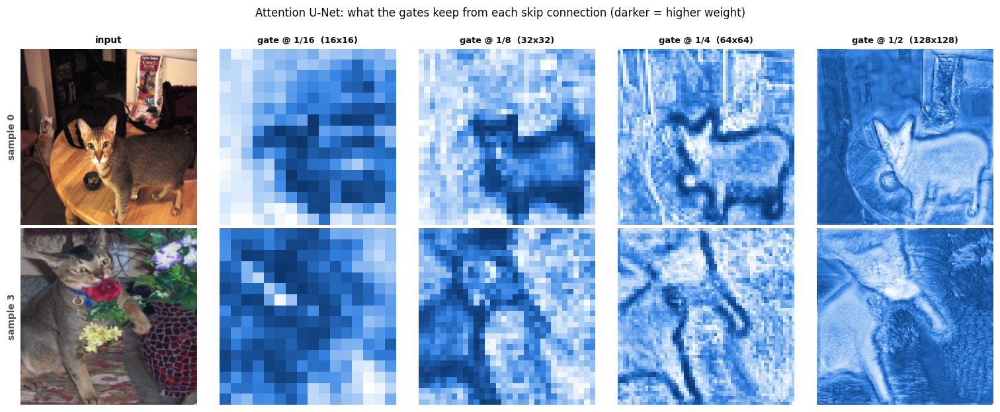

In [31]:
# ---------------------------------------------------- Figure: attention gates (Attention U-Net)
m = load_trained("Attention U-Net")
x, y = next(iter(eval_batches("test", 8)))
with torch.no_grad():
    _ = m(x)
attn = m.last_attn
fig, axes = plt.subplots(2, 5, figsize=(14, 5.6))
for r, b in enumerate([0, 3]):
    axes[r, 0].imshow(denormalize(x[b:b+1])[0].permute(1, 2, 0).cpu().numpy())
    axes[r, 0].set_ylabel(f"sample {b}", fontweight="bold", fontsize=9)
    for k, a in enumerate(attn):
        g = a[b, 0].float().cpu().numpy()
        axes[r, k+1].imshow(g, cmap=SEQ_BLUE)
        if r == 0:
            axes[r, k+1].set_title(f"gate @ 1/{2**(4-k)}  ({g.shape[0]}x{g.shape[1]})", fontsize=8.5)
    for a in axes[r]:
        no_axes(a)
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([]); axes[r, 0].grid(False)
axes[0, 0].set_title("input", fontsize=9)
fig.suptitle("Attention U-Net: what the gates keep from each skip connection (darker = higher weight)", y=1.0)
fig.tight_layout()
savefig(fig, "fig10_attention_gates")
del m; torch.cuda.empty_cache()

---
# Task 3 --- BRAG-UNet, a custom segmentation architecture

**B**oundary-**R**efined **A**ttention-**G**ated U-Net.

## A. Motivation

The motivation comes from three numbers measured on this dataset in section 2.2, not from a
general wish to combine good ideas.

**1. Object scale varies by more than an order of magnitude.** The pet covers 6.9% of the frame at
the 5th percentile and 58.7% at the 95th, with the full range running from under 1% to over 90%.
A plain U-Net decoder sees exactly one encoder map per decoder stage, so the scale at which it
reasons is *fixed by architecture* rather than chosen per image. FPN addresses this by summing
pyramid levels --- but it sums them with **equal, fixed weights**, which is still not a choice.
The natural fix is to let the network *weight the pyramid levels per image*.

**2. The border class is thin and it is where every model loses points.** It occupies 11.25% of
pixels and, as section 2.8 shows, its IoU sits far below the pet class for every architecture.
BASNet's insight applies directly: predicting a *correction* to a coarse mask is an easier
objective than predicting the mask, and the correction naturally concentrates on edges. BASNet's
refinement module is however a full second encoder-decoder, which is expensive.

**3. Background dominates.** 60.8% of pixels are background, much of it cluttered (grass, carpet,
furniture). Attention U-Net's gates are the cheapest known way to suppress irrelevant skip content
before it is concatenated.

BRAG-UNet therefore takes the context machinery from DeepLab, the gating from Attention U-Net and
the residual-refinement idea from BASNet, and adds three things of its own: a **scale-gated
fusion** that makes the pyramid weighting *learned and input-dependent*, a **lightweight
full-resolution refinement head** that costs a fraction of BASNet's RRM, and a **boundary-aware
loss** that puts extra weight exactly on the pixels the border class occupies.

## B. Architecture

```
                 ┌──────────── ResNet-34 encoder (ImageNet) ────────────┐
   input 256² ──▶│ c1 /2 ·64   c2 /4 ·64   c3 /8 ·128  c4 /16 ·256  c5 /32 ·512 │
                 └───┬──────────┬──────────┬──────────┬──────────┬──────┘
                     │          │          │          │          │
            1×1 lateral projections to a common width P = 64      │
                     │          │          │          │          ▼
                    l1         l2         l3         l4      ┌────────┐
                     │          │          │          │      │  ASPP  │  rates 6/12/18
                     └──────────┴────┬─────┴──────────┘      │ bridge │  + image pooling
                                     │                       └───┬────┘
                      ╔══════════════▼═══════════════╗           │
                      ║  SCALE-GATED FUSION  (ours)  ║           │
                      ║  resample l1..l5 to level r, ║           │
                      ║  GAP→MLP→softmax over the 5  ║           │
                      ║  levels, weighted sum        ║           │
                      ╚══════════════╤═══════════════╝           │
                                     │                           ▼
   decoder level r ◀── concat[ up(stream) , AttnGate(c_r) , fused_r ] ── conv×2
                                     │
                        /16 → /8 → /4 → /2 → /1
                                     ▼
                              coarse logits (3 ch)
                                     │
            ╔════════════════════════▼════════════════════════╗
            ║  BOUNDARY REFINEMENT HEAD (ours)                ║
            ║  [ input image ‖ coarse logits ] → 4 convs       ║
            ║  → residual  →  refined = coarse + residual      ║
            ╚════════════════════════╤════════════════════════╝
                                     ▼
                            refined logits (3 ch)
```

Deep supervision is attached to the coarse logits and to each decoder stage.

## C. What is borrowed and what is new

| Component | Origin | Status |
|---|---|---|
| ResNet-34 encoder | He *et al.* / ImageNet | **adopted**, identical to all other models here |
| ASPP bridge (rates 6/12/18 + image pooling) | DeepLabV3+ | **adopted** unchanged |
| Additive attention gates on skips | Attention U-Net (Oktay *et al.*) | **adopted** unchanged |
| Deep supervision | U-Net++ / BASNet | **adopted** |
| Residual refinement *concept* | BASNet | **adopted** as an idea, re-implemented far lighter |
| **Scale-gated multi-scale fusion** | — | **our modification**: FPN fuses levels with fixed equal weights; here a GAP→MLP→softmax produces **per-image, per-level** weights, so the network chooses which scale to trust for each input |
| **Lightweight boundary-refinement head** | — | **our modification**: BASNet's RRM is a 4-level encoder-decoder on the mask; ours is 4 convolutions at full resolution that also see **the input image**, so the correction can use raw edge evidence the decoder has already blurred away |
| **Boundary-aware loss term** | — | **our modification**: cross-entropy is re-weighted by `1 + λ·band`, where `band` marks pixels within 2 px of any class transition |

In [32]:
class ScaleGate(nn.Module):
    # OUR MODIFICATION. Fuse L pyramid levels (already resampled to one resolution) with
    # per-image, per-level softmax weights, instead of FPN's fixed equal-weight sum.
    def __init__(self, ch, n_levels, red=4):
        super().__init__()
        self.n = n_levels
        self.score = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(ch * n_levels, max(ch // red, 16), 1), nn.ReLU(inplace=True),
            nn.Conv2d(max(ch // red, 16), n_levels, 1))

    def forward(self, feats):
        w = self.score(torch.cat(feats, 1)).softmax(1)          # (B, L, 1, 1)
        out = feats[0] * w[:, 0:1]
        for i in range(1, self.n):
            out = out + feats[i] * w[:, i:i+1]
        return out, w


class BoundaryRefine(nn.Module):
    # OUR MODIFICATION. Full-resolution residual correction that also sees the input image.
    def __init__(self, n_classes=3, w=32):
        super().__init__()
        self.body = nn.Sequential(cbr(3 + n_classes, w), cbr(w, w),
                                  cbr(w, w, k=3, p=2, d=2), cbr(w, w))
        self.out = nn.Conv2d(w, n_classes, 3, padding=1)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)   # start as identity

    def forward(self, img, coarse):
        return coarse + self.out(self.body(torch.cat([img, coarse], 1)))


class BRAGUNet(nn.Module):
    def __init__(self, n_classes=3, pretrained=True, P=64,
                 use_scale_gate=True, use_refine=True, deep_sup=True):
        super().__init__()
        self.enc = ResNet34Encoder(pretrained)
        ch = self.enc.channels                       # [64,64,128,256,512]
        d  = [256, 128, 64, 32, 16]
        self.use_scale_gate, self.use_refine, self.deep_sup = use_scale_gate, use_refine, deep_sup

        self.lat  = nn.ModuleList([nn.Conv2d(c, P, 1) for c in ch])          # l1..l5
        self.aspp = ASPP(ch[4], d[0], rates=(6, 12, 18))                     # bridge @ /32
        self.gates = nn.ModuleList([ScaleGate(P, 5) for _ in range(4)])      # /16,/8,/4,/2

        self.att = nn.ModuleList([AttentionGate(d[0], ch[3], ch[3] // 2),
                                  AttentionGate(d[0], ch[2], ch[2] // 2),
                                  AttentionGate(d[1], ch[1], ch[1] // 2),
                                  AttentionGate(d[2], ch[0], ch[0] // 2)])
        fuse = P if use_scale_gate else 0
        self.dec = nn.ModuleList([
            nn.Sequential(cbr(d[0] + ch[3] + fuse, d[0]), cbr(d[0], d[0])),  # /16
            nn.Sequential(cbr(d[0] + ch[2] + fuse, d[1]), cbr(d[1], d[1])),  # /8
            nn.Sequential(cbr(d[1] + ch[1] + fuse, d[2]), cbr(d[2], d[2])),  # /4
            nn.Sequential(cbr(d[2] + ch[0] + fuse, d[3]), cbr(d[3], d[3])),  # /2
            nn.Sequential(cbr(d[3], d[4]), cbr(d[4], d[4]))])                # /1
        self.head = nn.Conv2d(d[4], n_classes, 1)
        self.refine = BoundaryRefine(n_classes) if use_refine else None
        self.side = nn.ModuleList([nn.Conv2d(c, n_classes, 1) for c in d[:4]])
        self.last_gate_w = None

    def forward(self, x):
        c = self.enc(x)
        lats = [self.lat[i](c[i]) for i in range(5)]
        y = self.aspp(c[4])
        feats, gw = [], []
        for k, ci in enumerate([3, 2, 1, 0]):                     # c4, c3, c2, c1
            ref = c[ci]
            y = up2(y, ref)
            skip, _ = self.att[k](y, ref)
            parts = [y, skip]
            if self.use_scale_gate:
                res = [F.interpolate(l, size=ref.shape[-2:], mode="bilinear", align_corners=False)
                       if l.shape[-2:] != ref.shape[-2:] else l for l in lats]
                f, w = self.gates[k](res)
                parts.append(f); gw.append(w)
            y = self.dec[k](torch.cat(parts, 1))
            feats.append(y)
        y = self.dec[4](up2(y))                                   # /2 -> /1
        coarse = self.head(y)
        refined = self.refine(denormalize(x), coarse) if self.use_refine else coarse
        self.last_gate_w = gw

        out = [refined]
        if self.training:
            if self.use_refine:
                out.append(coarse)
            if self.deep_sup:
                for s, f in zip(self.side, feats):
                    out.append(F.interpolate(s(f), size=x.shape[-2:],
                                             mode="bilinear", align_corners=False))
        return out

CUSTOM = "BRAG-UNet (ours)"
MODEL_ZOO[CUSTOM] = (BRAGUNet, PALETTE[7])
MODEL_COLOR[CUSTOM] = PALETTE[7]
_m = build(CUSTOM)
print(f"{CUSTOM}: {sum(p.numel() for p in _m.parameters())/1e6:.2f} M params, "
      f"{count_macs(_m)/1e9:.2f} GMACs, {latency(_m):.2f} ms")
del _m; torch.cuda.empty_cache()

BRAG-UNet (ours): 28.48 M params, 10.69 GMACs, 7.62 ms


  saved -> outputs/figures/fig11_bragunet_architecture.png


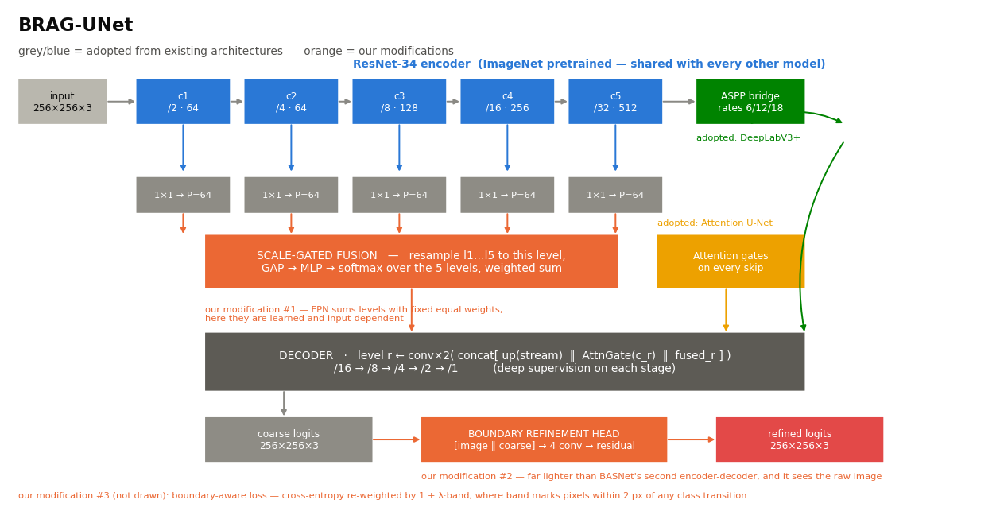

In [33]:
# ---------------------------------------------------- Figure: architecture schematic
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def box(ax, x, y, w, h, label, fc, tc="white", fs=8, lw=0):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.012,rounding_size=0.02",
                                fc=fc, ec="white", lw=lw))
    ax.text(x + w/2, y + h/2, label, ha="center", va="center", fontsize=fs, color=tc, zorder=5)

def arrow(ax, p, q, color=INK3, style="-|>", lw=1.3, rad=0.0):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=9,
                                 color=color, lw=lw, connectionstyle=f"arc3,rad={rad}",
                                 shrinkA=1, shrinkB=1))

fig, ax = plt.subplots(figsize=(14.5, 7.4))
ax.set_xlim(0, 100); ax.set_ylim(0, 56); ax.axis("off")

ENC, BRG, DECC, OURS, HEADC = PALETTE[0], PALETTE[5], "#5d5b55", PALETTE[1], PALETTE[7]

ax.text(1, 53.5, "BRAG-UNet", fontsize=15, fontweight="bold", color=INK)
ax.text(1, 50.8, "grey/blue = adopted from existing architectures      orange = our modifications",
        fontsize=9, color=INK2)

# encoder row
box(ax, 1, 43, 9, 5, "input\n256×256×3", "#b9b7ae", INK)
encs = [("c1\n/2 · 64", 13), ("c2\n/4 · 64", 24), ("c3\n/8 · 128", 35),
        ("c4\n/16 · 256", 46), ("c5\n/32 · 512", 57)]
for lab, x in encs:
    box(ax, x, 43, 9.5, 5, lab, ENC)
ax.text(35, 49.4, "ResNet-34 encoder  (ImageNet pretrained — shared with every other model)",
        fontsize=9, color=ENC, fontweight="bold")
arrow(ax, (10, 45.5), (13, 45.5))
for i in range(4):
    arrow(ax, (encs[i][1] + 9.5, 45.5), (encs[i+1][1], 45.5))

# ASPP bridge
box(ax, 70, 43, 11, 5, "ASPP bridge\nrates 6/12/18", BRG)
arrow(ax, (66.5, 45.5), (70, 45.5))
ax.text(70, 41.2, "adopted: DeepLabV3+", fontsize=7.5, color=BRG)

# lateral projections
for lab, x in encs:
    arrow(ax, (x + 4.75, 43), (x + 4.75, 37.5), color=ENC, rad=0)
    box(ax, x, 33, 9.5, 4, "1×1 → P=64", "#8e8c85", "white", fs=7.5)

# scale gate
box(ax, 20, 24.5, 42, 6, "SCALE-GATED FUSION   —   resample l1…l5 to this level,\n"
                         "GAP → MLP → softmax over the 5 levels, weighted sum", OURS, fs=9)
for lab, x in encs:
    arrow(ax, (x + 4.75, 33), (x + 4.75, 30.5), color=OURS, rad=0)
ax.text(20, 22.6, "our modification #1 — FPN sums levels with fixed equal weights;\n"
                  "here they are learned and input-dependent", fontsize=7.5, color=OURS, va="top")

# attention gates + decoder
box(ax, 66, 24.5, 15, 6, "Attention gates\non every skip", PALETTE[3])
ax.text(66, 31.6, "adopted: Attention U-Net", fontsize=7.5, color=PALETTE[3])

box(ax, 20, 13, 61, 6.5, "DECODER   ·   level r ← conv×2( concat[ up(stream)  ‖  AttnGate(c_r)  ‖  fused_r ] )\n"
                         "/16 → /8 → /4 → /2 → /1          (deep supervision on each stage)", DECC, fs=9)
arrow(ax, (41, 24.5), (41, 19.5), color=OURS)
arrow(ax, (73, 24.5), (73, 19.5), color=PALETTE[3])
arrow(ax, (75.5, 43), (85, 43), color=BRG, rad=-0.25)
arrow(ax, (85, 41), (81, 19.5), color=BRG, rad=0.2)

# heads
box(ax, 20, 5, 17, 5, "coarse logits\n256×256×3", "#8e8c85")
arrow(ax, (28, 13), (28, 10))
box(ax, 42, 5, 25, 5, "BOUNDARY REFINEMENT HEAD\n[image ‖ coarse] → 4 conv → residual", OURS, fs=8)
arrow(ax, (37, 7.5), (42, 7.5), color=OURS)
box(ax, 72, 5, 17, 5, "refined logits\n256×256×3", HEADC)
arrow(ax, (67, 7.5), (72, 7.5), color=OURS)
ax.text(42, 3.1, "our modification #2 — far lighter than BASNet's second encoder-decoder, and it sees the raw image",
        fontsize=7.5, color=OURS)
ax.text(1, 1.0, "our modification #3 (not drawn): boundary-aware loss — cross-entropy re-weighted by 1 + λ·band, "
                "where band marks pixels within 2 px of any class transition",
        fontsize=7.5, color=OURS)

savefig(fig, "fig11_bragunet_architecture")

## D. Training the custom model

Same dataset, same split, same optimiser, same schedule, same epochs, same batch size as the
seven reference models --- the only difference is the loss, which adds the boundary-aware
re-weighting term that is part of the contribution. The ablation below isolates how much each of
the three modifications is worth.

In [34]:
BOUNDARY_W = 1.5
CRIT_BOUNDARY = SegLoss(boundary_w=BOUNDARY_W)
HISTORIES[CUSTOM] = train_model(CUSTOM, criterion=CRIT_BOUNDARY)

[BRAG-UNet (ours)] checkpoint found -> skipping training


In [35]:
m = load_trained(CUSTOM)
met, pim, kept = test_full(m)
RESULTS[CUSTOM], PERIMG[CUSTOM], QUAL[CUSTOM] = met, pim, kept
print(f"{CUSTOM}: IoU {met['IoU']:.4f}  Dice {met['Dice']:.4f}  "
      f"PixAcc {met['Pixel Acc']:.4f}  mIoU {met['Mean IoU']:.4f}")
del m; torch.cuda.empty_cache()

BRAG-UNet (ours): IoU 0.8938  Dice 0.9439  PixAcc 0.9394  mIoU 0.8232


### Ablation --- is each modification actually earning its place?

Three further runs, each identical to the full model except that one component is removed. This is
the only way to tell a genuine contribution from a lucky seed.

| Run | Scale-gated fusion | Refinement head | Boundary-aware loss |
|---|---|---|---|
| full | yes | yes | yes |
| `-scalegate` | **no** (plain concat) | yes | yes |
| `-refine` | yes | **no** | yes |
| `-bloss` | yes | yes | **no** (plain CE+Dice) |

In [36]:
ABLATIONS = {
    "-- scale-gated fusion": dict(use_scale_gate=False, use_refine=True,  crit=CRIT_BOUNDARY),
    "-- refinement head":    dict(use_scale_gate=True,  use_refine=False, crit=CRIT_BOUNDARY),
    "-- boundary loss":      dict(use_scale_gate=True,  use_refine=True,  crit=CRITERION),
}
ABL_RES = {"BRAG-UNet (full)": RESULTS[CUSTOM]}
for label, kw in ABLATIONS.items():
    tag = "abl" + tag_of(label)
    set_seed(CFG.seed)
    mdl = BRAGUNet(n_classes=CFG.n_classes, pretrained=True,
                   use_scale_gate=kw["use_scale_gate"], use_refine=kw["use_refine"]).to(DEV)
    train_model(f"BRAG-UNet {label}", criterion=kw["crit"], model=mdl, tag=tag)
    set_seed(CFG.seed)
    mdl = BRAGUNet(n_classes=CFG.n_classes, pretrained=False,
                   use_scale_gate=kw["use_scale_gate"], use_refine=kw["use_refine"])
    mdl = load_trained(f"BRAG-UNet {label}", tag=tag, model=mdl)
    ABL_RES[f"BRAG-UNet {label}"], _, _ = test_full(mdl)
    del mdl; torch.cuda.empty_cache()

abl_df = results_table(ABL_RES)
abl_df["Δ Mean IoU"] = (abl_df["Mean IoU"] - abl_df.loc[0, "Mean IoU"]).round(4)
abl_df["Δ IoU"] = (abl_df["IoU"] - abl_df.loc[0, "IoU"]).round(4)
abl_df.to_csv(RES / "task3_ablation.csv", index=False)
display(abl_df)

[BRAG-UNet -- scale-gated fusion] checkpoint found -> skipping training


[BRAG-UNet -- refinement head] checkpoint found -> skipping training


[BRAG-UNet -- boundary loss] checkpoint found -> skipping training


,Model,IoU,Dice,Pixel Acc,Precision,Recall,F1,Mean IoU,Δ Mean IoU,Δ IoU
0,BRAG-UNet (full),0.8938,0.9439,0.9394,0.9368,0.9511,0.9439,0.8232,0.0000,0.0000
1,BRAG-UNet -- scale-gated fusion,0.8947,0.9444,0.9396,0.9403,0.9485,0.9444,0.8232,0.0000,0.0009
2,BRAG-UNet -- refinement head,0.8955,0.9448,0.9398,0.9376,0.9522,0.9448,0.8232,0.0000,0.0017
3,BRAG-UNet -- boundary loss,0.8935,0.9438,0.9394,0.9366,0.9510,0.9438,0.8236,0.0004,-0.0003


  saved -> outputs/figures/fig12_bragunet_analysis.png


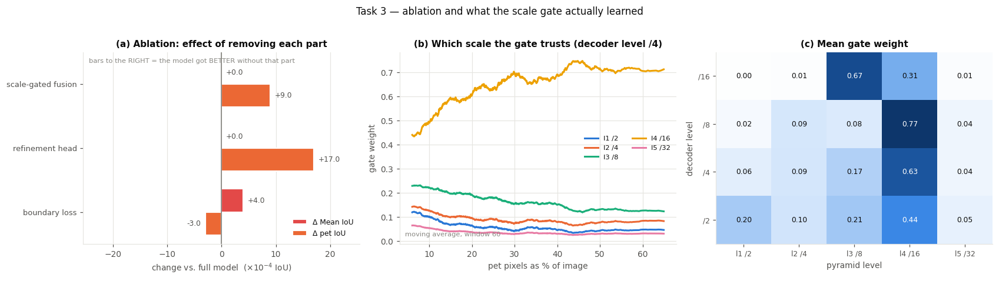

In [37]:
# ---------------------------------------------------- Figure: ablation + scale-gate behaviour
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.2))

# (a) ablation deltas, in units of 1e-4 so the near-zero values are legible
lab = [l.replace("BRAG-UNet -- ", "") for l in abl_df["Model"][1:]]
dm  = abl_df["Δ Mean IoU"][1:].values * 1e4
di  = abl_df["Δ IoU"][1:].values * 1e4
ys  = np.arange(len(lab))[::-1]; w = 0.36
ax[0].barh(ys + w/2, dm, w, color=PALETTE[7], edgecolor="white", linewidth=1.4, label="Δ Mean IoU")
ax[0].barh(ys - w/2, di, w, color=PALETTE[1], edgecolor="white", linewidth=1.4, label="Δ pet IoU")
span = max(abs(np.r_[dm, di]).max(), 1.0)
for y, (a, b) in enumerate(zip(dm, di)):
    yy = ys[y]
    ax[0].text(a + np.sign(a or 1)*span*0.05, yy + w/2, f"{a:+.1f}", va="center",
               ha="left" if a >= 0 else "right", fontsize=8, color=INK2)
    ax[0].text(b + np.sign(b or 1)*span*0.05, yy - w/2, f"{b:+.1f}", va="center",
               ha="left" if b >= 0 else "right", fontsize=8, color=INK2)
ax[0].axvline(0, color=INK3, lw=1.2)
ax[0].set_yticks(ys); ax[0].set_yticklabels(lab, fontsize=8.5)
ax[0].set_xlim(-span*1.5, span*1.5)
ax[0].set_xlabel("change vs. full model  ($\\times 10^{-4}$ IoU)")
ax[0].set_title("(a) Ablation: effect of removing each part")
ax[0].grid(axis="y", visible=False); ax[0].legend(fontsize=8, loc="lower right")
ax[0].text(0.02, 0.97, "bars to the RIGHT = the model got BETTER without that part",
           transform=ax[0].transAxes, fontsize=7.5, color=INK3, va="top")

# (b) learned scale-gate weights vs object size
m = load_trained(CUSTOM)
gw_all, fg_all = [], []
with torch.no_grad():
    for bi, (x, y) in enumerate(eval_batches("test", 32)):
        if bi >= 24:
            break
        _ = m(x)
        gw_all.append(torch.stack([g[:, :, 0, 0] for g in m.last_gate_w], 1).float().cpu().numpy())
        fg_all.append((y == FG).float().mean((1, 2)).cpu().numpy())
gw_all = np.concatenate(gw_all)        # (N, 4 decoder levels, 5 pyramid levels)
fg_all = np.concatenate(fg_all)
order  = np.argsort(fg_all)
lvl_names = ["l1 /2", "l2 /4", "l3 /8", "l4 /16", "l5 /32"]
gsel = gw_all[:, 2, :]                 # the /4 decoder level
k = 60
sm = np.stack([np.convolve(gsel[order, i], np.ones(k)/k, mode="valid") for i in range(5)], 1)
xf = np.convolve(fg_all[order], np.ones(k)/k, mode="valid") * 100
for i in range(5):
    ax[1].plot(xf, sm[:, i], color=PALETTE[i], label=lvl_names[i])
ax[1].set_xlabel("pet pixels as % of image"); ax[1].set_ylabel("gate weight")
ax[1].set_title("(b) Which scale the gate trusts (decoder level /4)")
ax[1].legend(fontsize=7.5, ncol=2)
ax[1].text(0.02, 0.04, f"moving average, window {k}", transform=ax[1].transAxes,
           fontsize=7.5, color=INK3)

# (c) mean gate weight per decoder level
im = ax[2].imshow(gw_all.mean(0), cmap=SEQ_BLUE, aspect="auto", vmin=0)
ax[2].set_xticks(range(5)); ax[2].set_xticklabels(lvl_names, fontsize=8)
ax[2].set_yticks(range(4)); ax[2].set_yticklabels(["/16", "/8", "/4", "/2"], fontsize=8)
ax[2].set_xlabel("pyramid level"); ax[2].set_ylabel("decoder level")
for i in range(4):
    for j in range(5):
        v = gw_all.mean(0)[i, j]
        ax[2].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                   color="white" if v > gw_all.mean(0).max()*0.55 else INK)
ax[2].set_title("(c) Mean gate weight"); ax[2].grid(False)
fig.suptitle("Task 3 — ablation and what the scale gate actually learned", y=1.02)
fig.tight_layout()
savefig(fig, "fig12_bragunet_analysis")
del m; torch.cuda.empty_cache()

## F. Comparison against the seven reference models

Everything in one table, sorted by mean IoU.

In [38]:
ALL = list(MODEL_ZOO)
full_df = results_table(RESULTS, ALL).sort_values("Mean IoU", ascending=False).reset_index(drop=True)
full_df.insert(0, "Rank", np.arange(1, len(full_df) + 1))
full_df.to_csv(RES / "task3_comparison.csv", index=False)
display(full_df.style.format({c: "{:.4f}" for c in HEADLINE})
        .background_gradient(cmap=SEQ_BLUE, subset=HEADLINE, axis=0))

cap2 = cap_df.copy()
m = build(CUSTOM)
cap2 = pd.concat([cap2, pd.DataFrame([{
    "Model": CUSTOM,
    "Params (M)": round(sum(p.numel() for p in m.parameters())/1e6, 2),
    "Encoder (M)": round(sum(p.numel() for p in m.enc.parameters())/1e6, 2),
    "Decoder (M)": round((sum(p.numel() for p in m.parameters())
                          - sum(p.numel() for p in m.enc.parameters()))/1e6, 2),
    "GMACs @256": round(count_macs(m)/1e9, 2),
    "Latency (ms)": round(latency(m), 2)}])], ignore_index=True)
del m; torch.cuda.empty_cache()
cap2 = cap2.merge(full_df[["Model", "Mean IoU", "IoU"]], on="Model")
cap2.to_csv(RES / "capacity_vs_accuracy.csv", index=False)
display(cap2)

,Rank,Model,IoU,Dice,Pixel Acc,Precision,Recall,F1,Mean IoU
0,1,FPN,0.8924,0.9431,0.9391,0.9422,0.9441,0.9431,0.8241
1,2,BRAG-UNet (ours),0.8938,0.9439,0.9394,0.9368,0.9511,0.9439,0.8232
2,3,BASNet,0.8941,0.9441,0.9392,0.9405,0.9477,0.9441,0.8230
3,4,U-Net++,0.8922,0.9430,0.9386,0.9403,0.9458,0.9430,0.8222
4,5,U-Net,0.8911,0.9424,0.9381,0.9387,0.9462,0.9424,0.8211
5,6,Attention U-Net,0.8940,0.9440,0.9390,0.9381,0.9500,0.9440,0.8208
6,7,SegFormer,0.8913,0.9426,0.9378,0.9366,0.9486,0.9426,0.8191
7,8,DeepLabV3+,0.8910,0.9423,0.9377,0.9384,0.9463,0.9423,0.8190


,Model,Params (M),Encoder (M),Decoder (M),GMACs @256,Latency (ms),Mean IoU,IoU
0,U-Net,24.44,21.28,3.15,7.81,4.05,0.8211,0.8911
1,U-Net++,25.77,21.28,4.49,13.01,5.17,0.8222,0.8922
2,FPN,25.07,21.28,3.79,10.63,4.57,0.8241,0.8924
3,Attention U-Net,24.57,21.28,3.29,7.95,5.49,0.8208,0.8940
4,BASNet,29.67,21.28,8.38,17.97,5.48,0.8230,0.8941
5,DeepLabV3+,26.71,21.28,5.43,13.63,4.16,0.8190,0.8910
6,SegFormer,3.71,NaN,NaN,1.66,7.02,0.8191,0.8913
7,BRAG-UNet (ours),28.48,21.28,7.19,10.69,8.09,0.8232,0.8938


  saved -> outputs/figures/fig13_accuracy_vs_cost.png


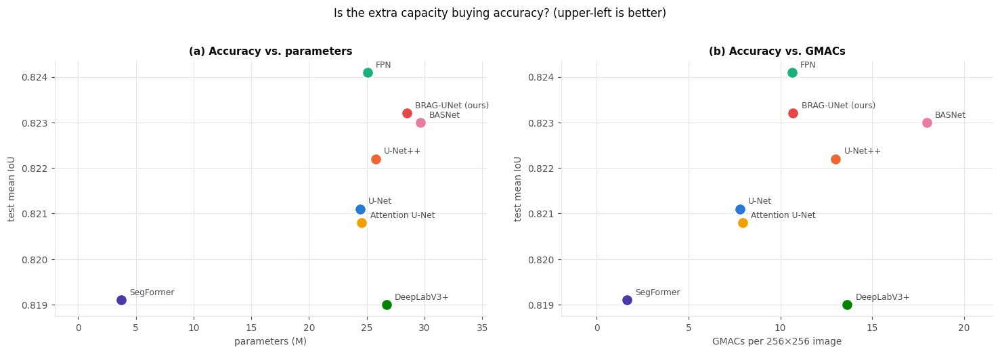

In [39]:
# ---------------------------------------------------- Figure: accuracy vs cost trade-off
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.6))
for _, r in cap2.iterrows():
    n = r["Model"]
    for k, xcol in enumerate(["Params (M)", "GMACs @256"]):
        ax[k].scatter(r[xcol], r["Mean IoU"], s=130, color=MODEL_COLOR[n],
                      edgecolor="white", linewidth=1.8, zorder=4)
        ax[k].annotate(n, (r[xcol], r["Mean IoU"]), textcoords="offset points",
                       xytext=(8, 5), fontsize=8, color=INK2)
for k, lab in enumerate(["parameters (M)", "GMACs per 256×256 image"]):
    ax[k].set_xlabel(lab); ax[k].set_ylabel("test mean IoU")
    ax[k].set_title(f"({'ab'[k]}) Accuracy vs. {lab.split()[0]}")
    ax[k].margins(x=0.22)
fig.suptitle("Is the extra capacity buying accuracy? (upper-left is better)", y=1.02)
fig.tight_layout()
savefig(fig, "fig13_accuracy_vs_cost")

  saved -> outputs/figures/fig14_qualitative_all.png


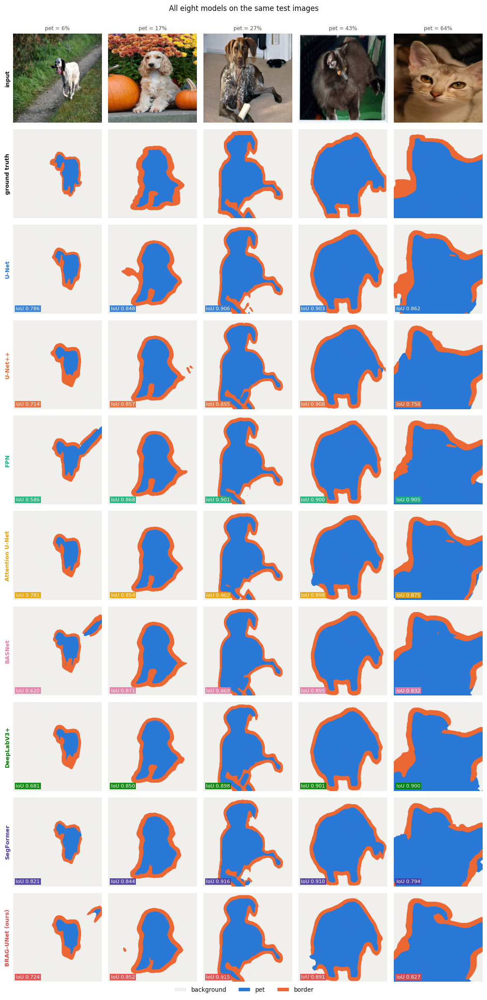

In [40]:
# ---------------------------------------------------- Figure: final qualitative, all 8 models
allm = list(MODEL_ZOO)
fig, axes = plt.subplots(len(allm) + 2, len(SHOW_IDX),
                         figsize=(2.05*len(SHOW_IDX), 2.05*(len(allm)+2)))
for c, i in enumerate(SHOW_IDX):
    im = np.asarray(CA["test"][0][i]); gt = np.asarray(CA["test"][1][i])
    axes[0, c].imshow(im)
    axes[0, c].set_title(f"pet = {test_fg[i]*100:.0f}%", fontsize=8, color=INK2, fontweight="normal")
    axes[1, c].imshow(colorize(gt))
    for r, name in enumerate(allm):
        pr = QUAL[name][i]
        axes[r+2, c].imshow(colorize(pr))
        iou = ((pr == FG) & (gt == FG)).sum() / max(((pr == FG) | (gt == FG)).sum(), 1)
        axes[r+2, c].text(0.03, 0.04, f"IoU {iou:.3f}", transform=axes[r+2, c].transAxes,
                          fontsize=7.5, color="white",
                          bbox=dict(fc=MODEL_COLOR[name], ec="none", pad=1.6, alpha=0.9))
    for r in range(len(allm)+2):
        no_axes(axes[r, c])
for r, lab in enumerate(["input", "ground truth"] + allm):
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([]); axes[r, 0].grid(False)
    axes[r, 0].set_ylabel(lab, fontsize=8.5, fontweight="bold", color=MODEL_COLOR.get(lab, INK))
handles = [plt.Rectangle((0, 0), 1, 1, fc=MASK_COLORS[i], ec="white", lw=1.2) for i in range(3)]
fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("All eight models on the same test images", y=1.0)
fig.tight_layout()
savefig(fig, "fig14_qualitative_all")

---
# Task 4 --- Self-captured images

## A. The images

Five photographs in `phone image/`. Their properties matter for the analysis, so they are measured
rather than assumed:

* **EXIF orientation must be honoured.** Two of the files carry rotation tags (orientation 6 and
  8). A pipeline that ignores them loads those images sideways, and every mask would then be
  scored against a rotated ground truth.
* **`5.jpg` is dominated by a person**, with the cat occupying only the lower part of the frame.
  The models have never seen a human during training, so this image is the strongest available
  probe of out-of-distribution behaviour. Only the **cat** is annotated as foreground.

## B. Manual annotation

The ground-truth masks are produced with **interactive GrabCut** --- a classical, non-learned
graph-cut algorithm --- seeded with a bounding rectangle and, where needed, hand-placed
foreground/background scribbles, then cleaned up (largest connected component, hole filling).
Each result is inspected visually and the seeds adjusted until the mask is correct.

**Why not a neural segmenter.** Using a deep segmentation model to generate the "ground truth"
and then scoring deep segmentation models against it is circular: it would measure agreement with
the annotator network rather than correctness, and would inflate every number in section F.
GrabCut is driven by colour/texture statistics and the human-supplied seeds only, so it is
independent of all eight trained models.

The annotation is therefore **tool-assisted rather than freehand**, which is standard practice in
annotation tools such as CVAT and labelme, and is stated explicitly here for transparency.

The 3-class trimap is completed the same way Oxford-IIIT Pet defines it: the **border** class is
the morphological band between a dilation and an erosion of the annotated object outline, so only
the outline has to be traced once.

In [41]:
PHONE_FILES = sorted([p for p in PHONE.glob("*.jpg")], key=lambda p: p.stem)
print(f"{len(PHONE_FILES)} self-captured images in '{PHONE.name}/'")

meta = []
for p in PHONE_FILES:
    raw = Image.open(p)
    ex = raw.getexif()
    fixed = ImageOps.exif_transpose(raw).convert("RGB")
    meta.append({"file": p.name, "stored": f"{raw.size[0]}x{raw.size[1]}",
                 "EXIF orient": ex.get(274, "-"),
                 "after transpose": f"{fixed.size[0]}x{fixed.size[1]}",
                 "MP": round(fixed.size[0]*fixed.size[1]/1e6, 1)})
phone_df = pd.DataFrame(meta)
phone_df.to_csv(RES / "task4_images.csv", index=False)
display(phone_df)

def load_phone(p):
    return np.asarray(ImageOps.exif_transpose(Image.open(p)).convert("RGB"), dtype=np.uint8)

5 self-captured images in 'phone image/'


,file,stored,EXIF orient,after transpose,MP
0,1.jpg,3000x4000,1,3000x4000,12.0
1,2.jpg,743x900,-,743x900,0.7
2,3.jpg,800x533,-,800x533,0.4
3,4.jpg,4000x3000,6,3000x4000,12.0
4,5.jpg,4640x3488,8,3488x4640,16.2


In [42]:
# --------------------------------------------------- interactive GrabCut annotation
# Seeds are in normalised image coordinates (0-1), placed by eye on each photograph.
#   rect : bounding box that certainly contains the animal
#   fg   : polylines drawn *inside* the animal      (certain foreground)
#   bg   : polylines drawn on background clutter    (certain background)
SEEDS = {
    "1": dict(rect=(0.14, 0.33, 0.95, 0.73),
              fg=[[(0.45, 0.47), (0.62, 0.50), (0.74, 0.54)], [(0.30, 0.52), (0.45, 0.56)]],
              bg=[[(0.02, 0.05), (0.98, 0.05)], [(0.02, 0.90), (0.98, 0.90)],
                  [(0.02, 0.20), (0.98, 0.20)]]),
    "2": dict(rect=(0.00, 0.06, 0.99, 0.99),
              fg=[[(0.45, 0.45), (0.55, 0.60), (0.45, 0.75)], [(0.20, 0.55), (0.30, 0.70)]],
              bg=[[(0.80, 0.05), (0.99, 0.10)], [(0.02, 0.02), (0.40, 0.04)],
                  [(0.88, 0.30), (0.99, 0.45)]]),
    "3": dict(rect=(0.05, 0.06, 0.97, 0.94),
              fg=[[(0.30, 0.35), (0.55, 0.35), (0.75, 0.30)], [(0.45, 0.55), (0.65, 0.55)]],
              bg=[[(0.02, 0.02), (0.98, 0.02)], [(0.02, 0.97), (0.98, 0.97)],
                  [(0.02, 0.50), (0.06, 0.50)]]),
    "4": dict(rect=(0.06, 0.06, 0.82, 0.95),
              fg=[[(0.45, 0.25), (0.40, 0.45), (0.33, 0.65)], [(0.25, 0.55), (0.45, 0.72)]],
              bg=[[(0.85, 0.02), (0.99, 0.98)], [(0.02, 0.02), (0.99, 0.03)],
                  [(0.02, 0.97), (0.99, 0.98)]]),
    "5": dict(rect=(0.08, 0.62, 0.74, 0.99),
              fg=[[(0.22, 0.72), (0.30, 0.78), (0.42, 0.86)], [(0.18, 0.80), (0.28, 0.88)]],
              bg=[[(0.02, 0.02), (0.98, 0.30)], [(0.50, 0.40), (0.98, 0.55)],
                  [(0.02, 0.40), (0.06, 0.60)], [(0.80, 0.70), (0.99, 0.99)]]),
}

def grabcut(img, seed, iters=7, work=700):
    h, w = img.shape[:2]
    sc = work / max(h, w)
    sm = cv2.resize(img, (int(round(w*sc)), int(round(h*sc))), interpolation=cv2.INTER_AREA)
    H, W = sm.shape[:2]
    gc = np.full((H, W), cv2.GC_BGD, np.uint8)
    x0, y0, x1, y1 = seed["rect"]
    gc[int(y0*H):int(y1*H), int(x0*W):int(x1*W)] = cv2.GC_PR_FGD
    th = max(2, int(0.012 * max(H, W)))
    for pts in seed.get("fg", []):
        cv2.polylines(gc, [np.array([(int(a*W), int(b*H)) for a, b in pts], np.int32)],
                      False, int(cv2.GC_FGD), th)
    for pts in seed.get("bg", []):
        cv2.polylines(gc, [np.array([(int(a*W), int(b*H)) for a, b in pts], np.int32)],
                      False, int(cv2.GC_BGD), th)
    bgd, fgd = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)
    cv2.grabCut(cv2.cvtColor(sm, cv2.COLOR_RGB2BGR), gc, None, bgd, fgd,
                iters, cv2.GC_INIT_WITH_MASK)
    m = np.isin(gc, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8)
    # clean-up: keep the largest component, close gaps, fill interior holes
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    n, lbl, st, _ = cv2.connectedComponentsWithStats(m, 8)
    if n > 1:
        m = (lbl == (1 + np.argmax(st[1:, cv2.CC_STAT_AREA]))).astype(np.uint8)
    m = ndi.binary_fill_holes(m.astype(bool)).astype(np.uint8)
    return cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)

def to_trimap(binary, band_px=3):
    # Oxford convention: border = the band between a dilation and an erosion of the outline
    k = np.ones((2*band_px+1, 2*band_px+1), np.uint8)
    d = cv2.dilate(binary, k); e = cv2.erode(binary, k)
    t = np.zeros_like(binary); t[binary > 0] = 1; t[(d - e) > 0] = 2
    return t

PHONE_IMG, PHONE_GT = {}, {}
for p in PHONE_FILES:
    img = load_phone(p)
    binm = grabcut(img, SEEDS[p.stem])
    img_s = np.asarray(Image.fromarray(img).resize((S, S), Image.BILINEAR), np.uint8)
    bin_s = np.asarray(Image.fromarray(binm*255).resize((S, S), Image.NEAREST), np.uint8) > 127
    tri_s = to_trimap(bin_s.astype(np.uint8), band_px=3)
    PHONE_IMG[p.stem], PHONE_GT[p.stem] = img_s, tri_s
    Image.fromarray((tri_s * 80).astype(np.uint8)).save(SELF / "masks" / f"{p.stem}_trimap.png")
    sh = np.bincount(tri_s.ravel(), minlength=3) / tri_s.size * 100
    print(f"  {p.name}: pet {sh[1]:5.1f}%   border {sh[2]:4.1f}%   background {sh[0]:5.1f}%")
print(f"\nmasks written to selfcaptured/masks/   (dataset border share for reference: "
      f"{DATASET_INFO['pixel_share_pct'][2]:.1f}%)")

  1.jpg: pet  10.2%   border  5.1%   background  84.7%


  2.jpg: pet  42.2%   border  9.0%   background  48.8%


  3.jpg: pet  34.4%   border  9.7%   background  55.8%


  4.jpg: pet  24.6%   border  9.3%   background  66.1%


  5.jpg: pet   8.1%   border  4.5%   background  87.3%

masks written to selfcaptured/masks/   (dataset border share for reference: 11.4%)


  saved -> outputs/figures/fig15_selfcaptured_annotation.png


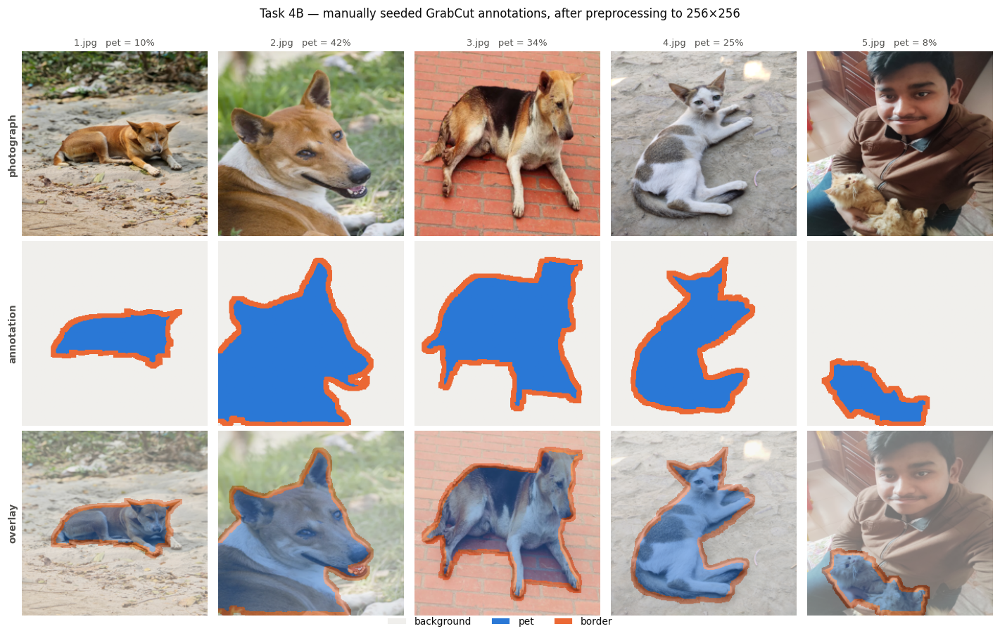

In [43]:
# ---------------------------------------------------- Figure: annotation review
keys = sorted(PHONE_IMG)
fig, axes = plt.subplots(3, len(keys), figsize=(2.6*len(keys), 8.0))
for c, k in enumerate(keys):
    im, gt = PHONE_IMG[k], PHONE_GT[k]
    axes[0, c].imshow(im)
    axes[1, c].imshow(colorize(gt))
    axes[2, c].imshow(im); axes[2, c].imshow(colorize(gt), alpha=0.45)
    axes[0, c].set_title(f"{k}.jpg   pet = {(gt==1).mean()*100:.0f}%", fontsize=8.5,
                         color=INK2, fontweight="normal")
    for r in range(3):
        no_axes(axes[r, c])
for r, lab in enumerate(["photograph", "annotation", "overlay"]):
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([]); axes[r, 0].grid(False)
    axes[r, 0].set_ylabel(lab, fontsize=9, fontweight="bold")
handles = [plt.Rectangle((0, 0), 1, 1, fc=MASK_COLORS[i], ec="white", lw=1.2) for i in range(3)]
fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.015))
fig.suptitle("Task 4B — manually seeded GrabCut annotations, after preprocessing to 256×256", y=1.0)
fig.tight_layout()
savefig(fig, "fig15_selfcaptured_annotation")

## C-F. Preprocessing, prediction and scoring

The self-captured images go through **exactly** the pipeline the test set uses: EXIF transpose,
RGB conversion, bilinear resize to 256x256, ImageNet normalisation. No test-time tricks, no
re-tuning. The same confusion-matrix machinery produces the same seven metrics.

In [44]:
PH_KEYS = sorted(PHONE_IMG)
ph_img = np.stack([PHONE_IMG[k] for k in PH_KEYS])
ph_gt  = np.stack([PHONE_GT[k]  for k in PH_KEYS])
ph_x   = normalize(to_float(torch.from_numpy(ph_img).to(DEV)))
ph_y   = torch.from_numpy(ph_gt).to(DEV).long()

SELF_RES, SELF_PRED, SELF_PER = {}, {}, {}
for name in MODEL_ZOO:
    m = load_trained(name)
    with torch.no_grad(), torch.amp.autocast("cuda", enabled=CFG.amp and DEV.type == "cuda"):
        pred = m(ph_x)[0].float().argmax(1)
    cm = ConfMat(); cm.update(pred, ph_y)
    SELF_RES[name] = metrics_from_cm(cm)
    SELF_PRED[name] = pred.cpu().numpy().astype(np.uint8)
    p1, t1 = (pred == FG), (ph_y == FG)
    SELF_PER[name] = (((p1 & t1).sum((1, 2)).double() + 1e-9) /
                      ((p1 | t1).sum((1, 2)).double() + 1e-9)).cpu().numpy()
    print(f"{name:20s} IoU {SELF_RES[name]['IoU']:.4f}  mIoU {SELF_RES[name]['Mean IoU']:.4f}")
    del m; torch.cuda.empty_cache()

self_df = results_table(SELF_RES).sort_values("Mean IoU", ascending=False).reset_index(drop=True)
self_df.to_csv(RES / "task4_results.csv", index=False)
display(self_df.style.format({c: "{:.4f}" for c in HEADLINE})
        .background_gradient(cmap=SEQ_BLUE, subset=HEADLINE, axis=0))

# per-image pet IoU, every model x every photo
per_img_df = pd.DataFrame({"Model": list(MODEL_ZOO),
                           **{f"{k}.jpg": [round(float(SELF_PER[n][i]), 4) for n in MODEL_ZOO]
                              for i, k in enumerate(PH_KEYS)}})
per_img_df["mean"] = per_img_df[[f"{k}.jpg" for k in PH_KEYS]].mean(1).round(4)
per_img_df.to_csv(RES / "task4_per_image.csv", index=False)
display(per_img_df)

U-Net                IoU 0.8072  mIoU 0.7463


U-Net++              IoU 0.8115  mIoU 0.7439


FPN                  IoU 0.8059  mIoU 0.7366


Attention U-Net      IoU 0.8130  mIoU 0.7542


BASNet               IoU 0.8179  mIoU 0.7495


...

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b0 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


SegFormer            IoU 0.8327  mIoU 0.7593


BRAG-UNet (ours)     IoU 0.8077  mIoU 0.7433


,Model,IoU,Dice,Pixel Acc,Precision,Recall,F1,Mean IoU
0,SegFormer,0.8327,0.9087,0.9324,0.9571,0.8650,0.9087,0.7593
1,Attention U-Net,0.8130,0.8968,0.9266,0.9539,0.8462,0.8968,0.7542
2,BASNet,0.8179,0.8998,0.9254,0.9532,0.8522,0.8998,0.7495
3,U-Net,0.8072,0.8933,0.9249,0.9432,0.8484,0.8933,0.7463
4,U-Net++,0.8115,0.8959,0.9241,0.9448,0.8518,0.8959,0.7439
5,BRAG-UNet (ours),0.8077,0.8936,0.9222,0.9566,0.8384,0.8936,0.7433
6,DeepLabV3+,0.8053,0.8922,0.9225,0.9527,0.8389,0.8922,0.7415
7,FPN,0.8059,0.8925,0.9195,0.9516,0.8404,0.8925,0.7366


,Model,1.jpg,2.jpg,3.jpg,4.jpg,5.jpg,mean
0,U-Net,0.7823,0.8846,0.7471,0.7480,0.8341,0.7992
1,U-Net++,0.8042,0.8908,0.7328,0.8041,0.7433,0.7950
2,FPN,0.7589,0.8863,0.7255,0.7849,0.8232,0.7958
3,Attention U-Net,0.8103,0.8587,0.7470,0.8180,0.8280,0.8124
4,BASNet,0.8052,0.8933,0.7444,0.7925,0.8090,0.8089
5,DeepLabV3+,0.8326,0.8750,0.7420,0.7716,0.7580,0.7958
6,SegFormer,0.8121,0.9191,0.7511,0.8046,0.8233,0.8220
7,BRAG-UNet (ours),0.8608,0.8938,0.7397,0.8067,0.5508,0.7704


  saved -> outputs/figures/fig16_selfcaptured_shift.png


,Model,Test IoU,Self IoU,Δ IoU,Test mIoU,Self mIoU,Δ mIoU
6,SegFormer,0.8913,0.8327,-0.0586,0.8191,0.7593,-0.0598
4,BASNet,0.8941,0.8179,-0.0761,0.8230,0.7495,-0.0735
1,U-Net++,0.8922,0.8115,-0.0808,0.8222,0.7439,-0.0783
3,Attention U-Net,0.8940,0.8130,-0.0810,0.8208,0.7542,-0.0666
0,U-Net,0.8911,0.8072,-0.0839,0.8211,0.7463,-0.0748
5,DeepLabV3+,0.8910,0.8053,-0.0857,0.8190,0.7415,-0.0775
7,BRAG-UNet (ours),0.8938,0.8077,-0.0861,0.8232,0.7433,-0.0799
2,FPN,0.8924,0.8059,-0.0865,0.8241,0.7366,-0.0875


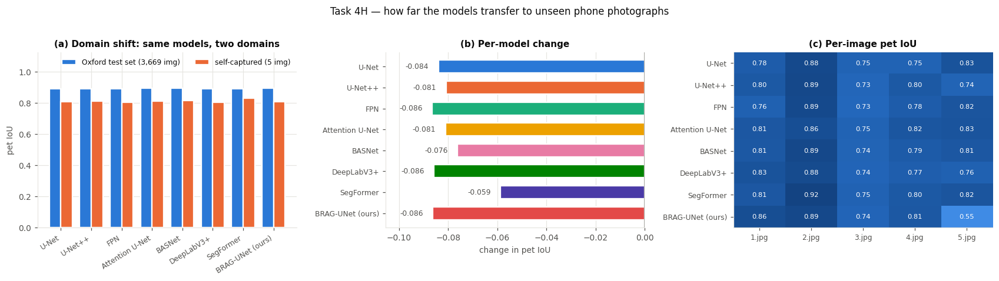

In [45]:
# ---------------------------------------------------- Figure: test vs self-captured drop
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.2))
names = list(MODEL_ZOO)
t_iou = np.array([RESULTS[n]["IoU"] for n in names])
s_iou = np.array([SELF_RES[n]["IoU"] for n in names])
xs, w = np.arange(len(names)), 0.38
ax[0].bar(xs - w/2, t_iou, w, color=PALETTE[0], edgecolor="white", linewidth=1.5,
          label="Oxford test set (3,669 img)")
ax[0].bar(xs + w/2, s_iou, w, color=PALETTE[1], edgecolor="white", linewidth=1.5,
          label=f"self-captured ({len(PH_KEYS)} img)")
ax[0].set_xticks(xs); ax[0].set_xticklabels(names, rotation=32, ha="right", fontsize=8)
ax[0].set_ylabel("pet IoU"); ax[0].set_title("(a) Domain shift: same models, two domains")
ax[0].set_ylim(0, max(t_iou.max(), s_iou.max()) * 1.26)
ax[0].legend(fontsize=8, loc="upper right", ncol=2)

drop = (s_iou - t_iou)
ax[1].barh(np.arange(len(names))[::-1], drop, color=[MODEL_COLOR[n] for n in names],
           height=0.62, edgecolor="white", linewidth=1.5)
for y, v in zip(np.arange(len(names))[::-1], drop):
    ax[1].text(v + (0.004 if v >= 0 else -0.004), y, f"{v:+.3f}", va="center",
               ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
ax[1].axvline(0, color=INK3, lw=1)
ax[1].set_yticks(np.arange(len(names))[::-1]); ax[1].set_yticklabels(names, fontsize=8)
ax[1].set_xlabel("change in pet IoU"); ax[1].set_title("(b) Per-model change")
ax[1].grid(axis="y", visible=False); ax[1].margins(x=0.22)

per = np.array([[SELF_PER[n][i] for i in range(len(PH_KEYS))] for n in names])
im = ax[2].imshow(per, cmap=SEQ_BLUE, aspect="auto", vmin=0, vmax=1)
ax[2].set_xticks(range(len(PH_KEYS))); ax[2].set_xticklabels([f"{k}.jpg" for k in PH_KEYS], fontsize=8)
ax[2].set_yticks(range(len(names))); ax[2].set_yticklabels(names, fontsize=8)
for i in range(len(names)):
    for j in range(len(PH_KEYS)):
        ax[2].text(j, i, f"{per[i,j]:.2f}", ha="center", va="center", fontsize=7.5,
                   color="white" if per[i, j] > 0.55 else INK)
ax[2].set_title("(c) Per-image pet IoU"); ax[2].grid(False)
fig.suptitle("Task 4H — how far the models transfer to unseen phone photographs", y=1.02)
fig.tight_layout()
savefig(fig, "fig16_selfcaptured_shift")

cmp_df = pd.DataFrame({"Model": names,
                       "Test IoU": t_iou.round(4), "Self IoU": s_iou.round(4),
                       "Δ IoU": drop.round(4),
                       "Test mIoU": [round(RESULTS[n]["Mean IoU"], 4) for n in names],
                       "Self mIoU": [round(SELF_RES[n]["Mean IoU"], 4) for n in names]})
cmp_df["Δ mIoU"] = (cmp_df["Self mIoU"] - cmp_df["Test mIoU"]).round(4)
cmp_df.to_csv(RES / "task4_domain_shift.csv", index=False)
display(cmp_df.sort_values("Δ IoU", ascending=False))

  saved -> outputs/figures/fig17_selfcaptured_1.png
  saved -> outputs/figures/fig17_selfcaptured_2.png


  saved -> outputs/figures/fig17_selfcaptured_3.png
  saved -> outputs/figures/fig17_selfcaptured_4.png


  saved -> outputs/figures/fig17_selfcaptured_5.png


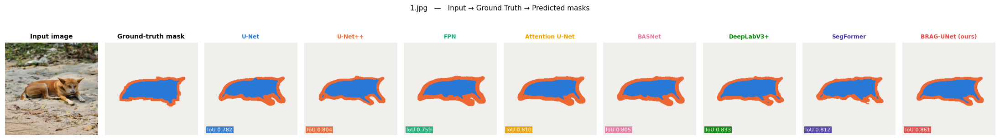

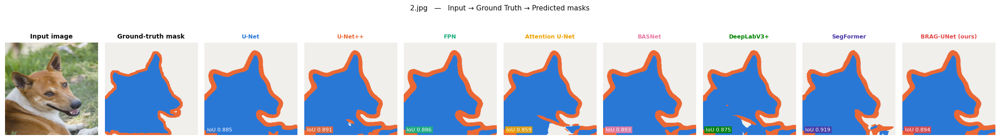

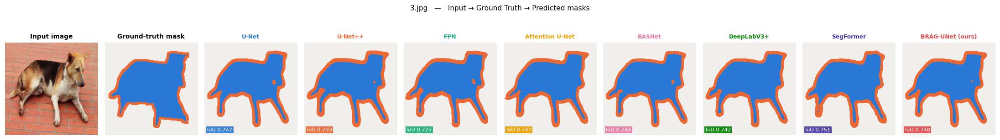

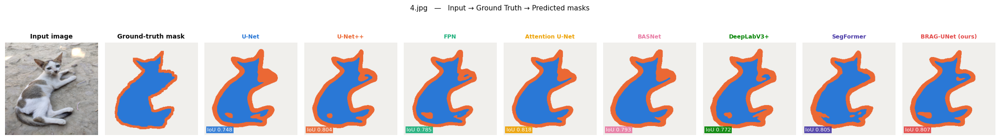

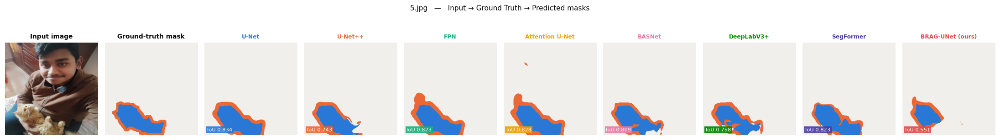

In [46]:
# ------------------------------------- Figure: Input -> Ground truth -> Prediction (per image)
for k_i, k in enumerate(PH_KEYS):
    cols = 2 + len(MODEL_ZOO)
    fig, axes = plt.subplots(1, cols, figsize=(2.0*cols, 2.5))
    axes[0].imshow(PHONE_IMG[k]);            axes[0].set_title("Input image", fontsize=9)
    axes[1].imshow(colorize(PHONE_GT[k]));   axes[1].set_title("Ground-truth mask", fontsize=9)
    for j, name in enumerate(MODEL_ZOO):
        axes[j+2].imshow(colorize(SELF_PRED[name][k_i]))
        axes[j+2].set_title(name, fontsize=8, color=MODEL_COLOR[name])
        axes[j+2].text(0.03, 0.04, f"IoU {SELF_PER[name][k_i]:.3f}",
                       transform=axes[j+2].transAxes, fontsize=7.5, color="white",
                       bbox=dict(fc=MODEL_COLOR[name], ec="none", pad=1.6, alpha=0.9))
    for a in axes:
        no_axes(a)
    fig.suptitle(f"{k}.jpg   —   Input → Ground Truth → Predicted masks", y=1.12, fontsize=10)
    fig.tight_layout()
    savefig(fig, f"fig17_selfcaptured_{k}")

In [47]:
# ---------------------------------------------------- consolidated result export for the report
summary = {
    "dataset": DATASET_INFO,
    "config": asdict(CFG),
    "hardware": HARDWARE,
    "task2_test": {n: {k: RESULTS[n][k] for k in HEADLINE} for n in MODEL_ZOO},
    "task2_per_class": {n: {f"IoU[{c}]": RESULTS[n][f"IoU[{c}]"] for c in CLASS_NAMES}
                        for n in MODEL_ZOO},
    "task3_ablation": {n: {k: ABL_RES[n][k] for k in HEADLINE} for n in ABL_RES},
    "task4_self": {n: {k: SELF_RES[n][k] for k in HEADLINE} for n in MODEL_ZOO},
    "task4_per_image": {n: {f"{k}.jpg": float(SELF_PER[n][i]) for i, k in enumerate(PH_KEYS)}
                        for n in MODEL_ZOO},
    "convergence": {n: {"best_val_miou": max(h["val_miou"]),
                        "best_epoch": int(np.argmax(h["val_miou"])) + 1,
                        "minutes": h.get("total_min")} for n, h in HISTORIES.items()},
}
(RES / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("wrote outputs/results/summary.json")
print(f"\nfigures produced: {len(sorted(FIG.glob('*.png')))}")
for p in sorted(FIG.glob("*.png")):
    print("  ", p.name)

wrote outputs/results/summary.json

figures produced: 21
   fig01_dataset_samples.png
   fig02_dataset_stats.png
   fig03_augmentation.png
   fig04_model_capacity.png
   fig05_training_curves.png
   fig06_metric_comparison.png
   fig07_confusion_matrices.png
   fig08_qualitative.png
   fig09_diagnostics.png
   fig10_attention_gates.png
   fig11_bragunet_architecture.png
   fig12_bragunet_analysis.png
   fig13_accuracy_vs_cost.png
   fig14_qualitative_all.png
   fig15_selfcaptured_annotation.png
   fig16_selfcaptured_shift.png
   fig17_selfcaptured_1.png
   fig17_selfcaptured_2.png
   fig17_selfcaptured_3.png
   fig17_selfcaptured_4.png
   fig17_selfcaptured_5.png


---
## Where the written analysis lives

Every number, table and figure this notebook produces is written to `outputs/results/` and
`outputs/figures/`. The detailed discussion --- Task 1's architectural reasoning, the
column-by-column reading of the Task 2C comparison, the advantages/limitations of BRAG-UNet
(Task 3G) and the domain-shift analysis for the self-captured photographs (Task 4H) --- is in the
accompanying report, which reads these artefacts directly.